# 03 · Segmentación ABC × XYZ por etapas auditables

Cada etapa es una función con una sola responsabilidad, invocada en su propia celda, que devuelve un objeto inspeccionable. Todo vive en memoria: el notebook no escribe archivos.

Ventana: d_122 a d_1941 (Y1–Y5, sin los 121 días de historia previa). Train = Y1–Y4; test = Y5. Lo que se estima (umbrales de racha y cortes) usa solo train.

In [1]:
import os
import sys
import warnings
from math import ceil, log
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.sandbox.stats.runs import runstest_1samp

from src.config import all_years, load_validated_config, train_end
from src.data import active_stores_by_item, load_interim
from src.segmentation import zero_breakdown, zero_runs

pd.set_option("display.max_columns", 30)
%matplotlib inline

cfg = load_validated_config()
years = all_years(cfg)
START_D, END_D = years["Y1"][0], years["Y5"][1]
TRAIN_END = train_end(cfg)
TEST_START = TRAIN_END + 1
ZERO_ALPHA = cfg["segmentation"]["zero_alpha"]   # α de LONG_RUN
RUNS_ALPHA = 0.01                                # α de la prueba de rachas (diagnóstico)
LONG_RUN_FALLBACK = cfg["segmentation"]["long_run"]

pd.Series({"START_D": START_D, "TRAIN_END": TRAIN_END, "TEST_START": TEST_START, "END_D": END_D,
           "ZERO_ALPHA": ZERO_ALPHA, "RUNS_ALPHA": RUNS_ALPHA, "LONG_RUN_FALLBACK": LONG_RUN_FALLBACK},
          name="parámetro").to_frame()

,parámetro
START_D,122.00
TRAIN_END,1577.00
TEST_START,1578.00
END_D,1941.00
ZERO_ALPHA,0.01
RUNS_ALPHA,0.01
LONG_RUN_FALLBACK,7.00


## Etapa 1 · Carga, inspección y tratamiento de ceros

### 1.0 · Carga

**Qué hace:** lee los intermedios por artículo (unidades y gasto por día) y los pasa a DataFrames artículo × día, de d_122 a d_1941.
**Entra:** `data/interim/` (solo lectura). **Sale:** `units`, `spend` (DataFrames) y `launch_d` (Series, primer día con precio).
**Revisar:** 3,049 artículos × 1,820 días; NaN = día sin dato (prelanzamiento o enmascarado en la validación).

In [2]:
def to_daily_frame(arr, item_ids, start_d, end_d):
    """Recorta un arreglo artículo × día (columna j = día j + 1) a [start_d, end_d] como DataFrame."""
    return pd.DataFrame(
        np.asarray(arr[:, start_d - 1 : end_d], dtype=float),
        index=pd.Index(np.asarray(item_ids, dtype=object), name="item_id"),
        columns=[f"d_{d}" for d in range(start_d, end_d + 1)],
    )


agg = load_interim(cfg, END_D)
units = to_daily_frame(agg["item_units"], agg["item_ids"], START_D, END_D)
spend = to_daily_frame(agg["item_spend"], agg["item_ids"], START_D, END_D)
launch_d = pd.Series(agg["item_launch_d"], index=units.index, name="launch_d")

print("units:", units.shape, "· spend:", spend.shape)
display(units.iloc[:5, :8], spend.iloc[:5, :8])
display(launch_d.describe().to_frame().T)

units: (3049, 1820) · spend: (3049, 1820)


,d_122,d_123,d_124,d_125,d_126,d_127,d_128,d_129
item_id,,,,,,,,
FOODS_1_001,4.0,10.0,9.0,12.0,15.0,9.0,21.0,5.0
FOODS_1_002,2.0,1.0,1.0,4.0,8.0,3.0,0.0,7.0
FOODS_1_003,4.0,6.0,13.0,6.0,8.0,10.0,5.0,18.0
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,d_122,d_123,d_124,d_125,d_126,d_127,d_128,d_129
item_id,,,,,,,,
FOODS_1_001,8.00,20.000000,18.000000,24.000000,30.000000,18.000000,42.000000,10.000000
FOODS_1_002,16.16,7.880000,7.880000,31.919999,63.040001,23.640000,0.000000,55.160001
FOODS_1_003,11.52,17.280001,37.440001,17.280001,23.040001,28.800001,14.400001,51.840002
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


,count,mean,std,min,25%,50%,75%,max
launch_d,3049.0,339.011151,439.745634,1.0,1.0,29.0,673.0,1527.0


### 1.0 · Inspección de ceros (como en la 6.4 del nb 02)

**Qué hace:** con las funciones del módulo, lista las rachas de ceros (`zero_runs`) y descompone los días con cero de cada artículo (`zero_breakdown`) en `leading`, `trailing`, `long_run` (interna ≥ 7 días, el valor fijo del nb 02) y `short`. Cuenta también las tiendas con dato por día.
**Entra:** `agg` y las unidades por tienda. **Sale:** `stores` (arreglo), `runs_eda` y `zeros_eda` (DataFrames).
**Revisar:** que las cifras se parezcan a las del nb 02 (237,143 rachas sobre la misma ventana). Es solo diagnóstico: el tratamiento de las celdas 1.1–1.4 no usa este `LONG_RUN = 7`.

In [3]:
series_data = load_interim(cfg, END_D, series_level=True)
stores = active_stores_by_item(series_data["units"], series_data["series_index"])
del series_data
print("tiendas con dato por artículo y día:", stores.shape)

tiendas con dato por artículo y día: (3049, 1941)


In [4]:
runs_eda = zero_runs(agg, START_D, END_D)
print(f"rachas de ceros: {len(runs_eda):,}")
display(runs_eda.head())
display(runs_eda.groupby("position")["length"].describe())

rachas de ceros: 237,143


,item_id,position,start_d,end_d,length
0,FOODS_1_001,internal,189,189,1
1,FOODS_1_001,internal,192,270,79
2,FOODS_1_001,internal,273,276,4
3,FOODS_1_001,internal,331,331,1
4,FOODS_1_001,internal,697,697,1


,count,mean,std,min,25%,50%,75%,max
position,,,,,,,,
internal,235607.0,2.832114,10.920861,1.0,1.0,1.0,2.0,1249.0
leading,1428.0,11.062325,51.540851,1.0,2.0,4.0,6.0,1054.0
trailing,108.0,7.750000,23.000660,1.0,1.0,1.0,3.5,207.0


In [5]:
LONG_RUN_EDA = 7  # valor fijo del nb 02, solo para esta inspección
zeros_eda = zero_breakdown(agg, START_D, END_D, LONG_RUN_EDA, active_stores=stores, runs=runs_eda)
parts = ["leading", "short", "long_run", "trailing"]
assert (zeros_eda[parts].sum(axis=1) == zeros_eda["zero_days"]).all()
display(zeros_eda.head())
totals = zeros_eda[parts].sum()
display(pd.DataFrame({"días con cero": totals, "% de los ceros": totals / totals.sum() * 100}).round(2))
display(zeros_eda[["active_days", "zero_days", "max_internal_run", "mean_active_stores"]].describe().round(2))

,item_id,active_days,zero_days,leading,trailing,long_run,short,n_long_runs,max_internal_run,mean_active_stores
0,FOODS_1_001,1820,188,0,0,151,37,5,79,10.0
1,FOODS_1_002,1820,76,0,0,0,76,0,2,10.0
2,FOODS_1_003,1820,31,0,0,0,31,0,2,10.0
3,FOODS_1_004,1542,149,4,0,114,31,5,54,10.0
4,FOODS_1_005,1820,436,84,0,275,77,17,60,10.0


,días con cero,% de los ceros
leading,15797,2.31
short,339779,49.68
long_run,327487,47.89
trailing,837,0.12


,active_days,zero_days,max_internal_run,mean_active_stores
count,3049.00,3049.00,3049.00,3049.00
mean,1539.76,224.30,41.84,9.61
std,393.01,233.73,73.38,0.66
min,415.00,1.00,1.00,4.03
25%,1269.00,41.00,4.00,9.46
50%,1820.00,144.00,14.00,9.90
75%,1820.00,337.00,55.00,10.00
max,1820.00,1423.00,1249.00,10.00


### 1.1 · Ciclo de vida

**Qué hace:** `lifecycle_bounds` toma el primer y el último día con venta > 0 de cada artículo; `trim_lifecycle` pone NaN fuera de ese intervalo. Así se recortan los ceros de arranque (entre el primer precio y la primera venta) y los finales (después de la última venta).
Se hace dos veces:
- **Serie completa (d_122–d_1941):** es el recorte que se aplica a los datos.
- **Solo train (d_122–d_1577):** solo sirve para medir n y p₀ en 1.2–1.3. Si un artículo deja de vender en Y4 y vuelve en Y5, en la serie completa esos ceros serían internos; con el ciclo de train no lo son, así que Y5 no influye en el umbral.

**Entra:** `units`. **Sale:** `bounds`, `units_lc` (serie completa recortada), `bounds_train`, `units_lc_train`.
**Revisar:** que los ceros recortados coincidan con `leading + trailing` de la inspección.

In [6]:
def lifecycle_bounds(units):
    """Primer y último día con venta > 0 de cada artículo dentro de las columnas de `units`."""
    days = np.array([int(c[2:]) for c in units.columns])
    sold = units.to_numpy() > 0
    has_sale = sold.any(axis=1)
    first = np.where(has_sale, days[sold.argmax(axis=1)], np.nan)
    last = np.where(has_sale, days[len(days) - 1 - sold[:, ::-1].argmax(axis=1)], np.nan)
    out = pd.DataFrame({"first_sale_d": first, "last_sale_d": last}, index=units.index)
    out["lifecycle_days"] = out["last_sale_d"] - out["first_sale_d"] + 1
    return out


bounds = lifecycle_bounds(units)
display(bounds.join(launch_d).head())
display(bounds.describe().round(1))

,first_sale_d,last_sale_d,lifecycle_days,launch_d
item_id,,,,
FOODS_1_001,122.0,1941.0,1820.0,1.0
FOODS_1_002,122.0,1941.0,1820.0,1.0
FOODS_1_003,122.0,1941.0,1820.0,1.0
FOODS_1_004,404.0,1941.0,1538.0,400.0
FOODS_1_005,206.0,1941.0,1736.0,1.0


,first_sale_d,last_sale_d,lifecycle_days
count,3049.0,3049.0,3049.0
mean,407.4,1940.7,1534.3
std,393.2,4.5,393.3
min,122.0,1734.0,414.0
25%,122.0,1941.0,1261.0
50%,125.0,1941.0,1815.0
75%,681.0,1941.0,1820.0
max,1528.0,1941.0,1820.0


In [7]:
def trim_lifecycle(units, bounds):
    """Copia de `units` con NaN antes de `first_sale_d` y después de `last_sale_d`."""
    days = np.array([int(c[2:]) for c in units.columns])
    inside = (days >= bounds["first_sale_d"].to_numpy()[:, None]) & (days <= bounds["last_sale_d"].to_numpy()[:, None])
    return units.where(inside)


units_lc = trim_lifecycle(units, bounds)
trimmed = ((units == 0) & units_lc.isna()).sum(axis=1)
assert (trimmed.to_numpy() == (zeros_eda["leading"] + zeros_eda["trailing"]).to_numpy()).all()
print(f"ceros recortados: {trimmed.sum():,} en {(trimmed > 0).sum():,} artículos (= leading + trailing de la inspección)")
display(trimmed.describe().to_frame("ceros recortados por artículo").T)

ceros recortados: 16,634 en 1,479 artículos (= leading + trailing de la inspección)


,count,mean,std,min,25%,50%,75%,max
ceros recortados por artículo,3049.0,5.455559,35.961722,0.0,0.0,0.0,4.0,1054.0


In [8]:
units_train = units.loc[:, :f"d_{TRAIN_END}"]
bounds_train = lifecycle_bounds(units_train)
units_lc_train = trim_lifecycle(units_train, bounds_train)
print("units_lc_train:", units_lc_train.shape)
moved = bounds_train["last_sale_d"] < bounds["last_sale_d"].clip(upper=TRAIN_END)
print(f"artículos cuyo ciclo de train termina antes que el de la serie completa recortada a train: {moved.sum():,}")
display(bounds_train.describe().round(1))

units_lc_train: (3049, 1456)
artículos cuyo ciclo de train termina antes que el de la serie completa recortada a train: 366


,first_sale_d,last_sale_d,lifecycle_days
count,3049.0,3049.0,3049.0
mean,407.4,1574.5,1168.0
std,393.2,19.3,393.6
min,122.0,976.0,35.0
25%,122.0,1577.0,896.0
50%,125.0,1577.0,1447.0
75%,681.0,1577.0,1456.0
max,1528.0,1577.0,1456.0


### 1.2 · Prueba de rachas de Wald–Wolfowitz (diagnóstico)

**Qué hace:** sobre la serie activo (venta > 0) / inactivo (venta = 0) de cada artículo dentro de su ciclo de vida en train, cuenta las rachas y aplica `runstest_1samp` (bilateral, sin corrección). z < 0 = menos rachas que el azar = ceros agrupados. Los días NaN se saltan.
**Entra:** `units_lc_train`. **Sale:** `runs_test` (DataFrame: `n_days, n_zero, n_runs, expected_runs, z, p_value, clustered`).
**Revisar:** % de artículos con ceros agrupados (`p < 0,01` y `z < 0`). Es descriptivo: **no decide qué se enmascara**.

In [9]:
def runs_test_by_item(units_lc, alpha):
    """Prueba de rachas de Wald–Wolfowitz sobre la serie venta / sin venta de cada artículo."""
    rows = []
    for item_id, row in units_lc.iterrows():
        zero = row.dropna().to_numpy() == 0
        n, n0 = len(zero), int(zero.sum())
        n_runs = int(1 + (zero[1:] != zero[:-1]).sum()) if n else 0
        expected = 2 * n0 * (n - n0) / n + 1 if n else np.nan
        z = p = np.nan
        if 0 < n0 < n:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)
                z, p = runstest_1samp(zero.astype(float), cutoff=0.5, correction=False)
        rows.append((item_id, n, n0, n_runs, expected, z, p))
    out = pd.DataFrame(rows, columns=["item_id", "n_days", "n_zero", "n_runs", "expected_runs", "z", "p_value"])
    out["clustered"] = (out["p_value"] < alpha) & (out["z"] < 0)
    return out.set_index("item_id")


runs_test = runs_test_by_item(units_lc_train, RUNS_ALPHA)
display(runs_test.head())

,n_days,n_zero,n_runs,expected_runs,z,p_value,clustered
item_id,,,,,,,
FOODS_1_001,1456,179,53,314.987637,-31.878100,5.371749e-223,True
FOODS_1_002,1456,57,107,110.537088,-1.237393,2.159412e-01,False
FOODS_1_003,1456,22,43,44.335165,-1.189037,2.344249e-01,False
FOODS_1_004,1174,71,25,134.412266,-28.193762,6.973639e-175,True
FOODS_1_005,1372,351,95,523.406706,-30.393612,6.671578e-203,True


,valor
artículos,3049.00
con prueba definida (0 < ceros < n),3046.00
"agrupados (p < 0.01, z < 0)",2135.00
% agrupados sobre los definidos,70.09
"más alternados que el azar (p < 0.01, z > 0)",0.00
sin evidencia (p ≥ 0.01),911.00


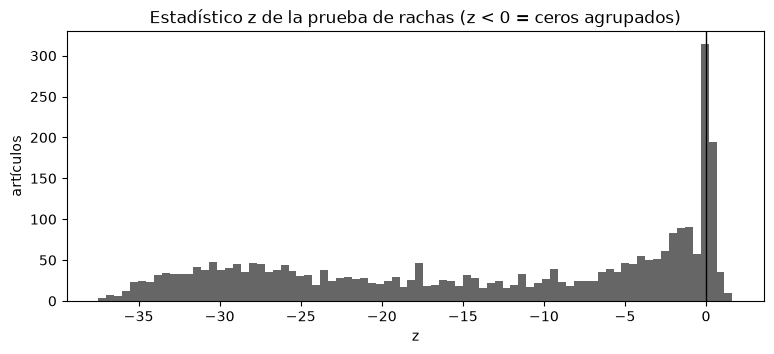

In [10]:
defined = runs_test["p_value"].notna()
summary_rt = pd.Series({
    "artículos": len(runs_test),
    "con prueba definida (0 < ceros < n)": int(defined.sum()),
    f"agrupados (p < {RUNS_ALPHA}, z < 0)": int(runs_test["clustered"].sum()),
    f"% agrupados sobre los definidos": runs_test.loc[defined, "clustered"].mean() * 100,
    f"más alternados que el azar (p < {RUNS_ALPHA}, z > 0)": int(((runs_test["p_value"] < RUNS_ALPHA) & (runs_test["z"] > 0)).sum()),
    f"sin evidencia (p ≥ {RUNS_ALPHA})": int((runs_test["p_value"] >= RUNS_ALPHA).sum()),
}, name="valor")
display(summary_rt.to_frame().round(2))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(runs_test["z"].dropna(), bins=80, color="0.4")
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Estadístico z de la prueba de rachas (z < 0 = ceros agrupados)", xlabel="z", ylabel="artículos")
plt.show()

### 1.3 · LONG_RUN por artículo

**Qué hace:** con n = días con dato dentro del ciclo de vida en train y p₀ = fracción de esos días con venta 0:

LONG_RUN = ceil( ln[ n·(1 − p₀) ÷ α ] ÷ ln(1 ÷ p₀) ), con α = 0,01.

Es el menor k con n·(1 − p₀)·p₀ᵏ ≤ α: el número esperado de rachas de ceros de largo ≥ k bajo días independientes es a lo más α. **Fallback = 7** y su motivo en `reason`: `no_zeros` (p₀ = 0), `all_zeros` (p₀ = 1) o `no_sales_train` (sin ventas en train). Se excluyen los artículos lanzados en Y5 (`launch_d` ≥ d_1578).
**Entra:** `units_lc_train`, `launch_d`. **Sale:** `thresholds` (DataFrame: `n_days, n_zero, p0, long_run_raw, long_run, source, reason`).
**Revisar:** cuántos usan el fallback y por qué, y la distribución de LONG_RUN.

In [11]:
def long_run_thresholds(units_lc, launch_d, test_start, alpha, fallback):
    """Umbral LONG_RUN de cada artículo con la cota de la racha más larga; fallback si no se puede."""
    rows = []
    eligible = launch_d.reindex(units_lc.index) < test_start
    for item_id, row in units_lc[eligible].iterrows():
        x = row.dropna().to_numpy()
        n, n0 = len(x), int((x == 0).sum())
        p0 = n0 / n if n else np.nan
        raw, reason = np.nan, None
        if n == 0:
            reason = "no_sales_train"
        elif p0 == 0:
            reason = "no_zeros"
        elif p0 == 1:
            reason = "all_zeros"
        else:
            raw = log(n * (1 - p0) / alpha) / log(1 / p0)
        long_run = fallback if reason else ceil(raw)
        rows.append((item_id, n, n0, p0, raw, long_run, "fallback" if reason else "formula", reason))
    out = pd.DataFrame(rows, columns=["item_id", "n_days", "n_zero", "p0", "long_run_raw", "long_run", "source", "reason"])
    return out.set_index("item_id")


thresholds = long_run_thresholds(units_lc_train, launch_d, TEST_START, ZERO_ALPHA, LONG_RUN_FALLBACK)
excluded_y5 = units.index.difference(thresholds.index)
print(f"artículos con umbral: {len(thresholds):,} · excluidos por lanzamiento en Y5: {len(excluded_y5)}")
display(thresholds.head(10))

artículos con umbral: 3,049 · excluidos por lanzamiento en Y5: 0


,n_days,n_zero,p0,long_run_raw,long_run,source,reason
item_id,,,,,,,
FOODS_1_001,1456,179,0.122940,5.609298,6,formula,NaN
FOODS_1_002,1456,57,0.039148,3.656553,4,formula,NaN
FOODS_1_003,1456,22,0.015110,2.832119,3,formula,NaN
FOODS_1_004,1174,71,0.060477,4.138653,5,formula,NaN
FOODS_1_005,1372,351,0.255831,8.460521,9,formula,NaN
FOODS_1_006,1456,7,0.004808,2.226457,3,formula,NaN
FOODS_1_008,1314,368,0.280061,9.002104,10,formula,NaN
FOODS_1_009,1177,393,0.333900,10.273890,11,formula,NaN
FOODS_1_010,1452,254,0.174931,6.707484,7,formula,NaN


In [12]:
display(thresholds.groupby(["source", "reason"], dropna=False).size().rename("artículos").to_frame())
display(thresholds[thresholds["source"] == "fallback"])
display(thresholds["long_run"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("LONG_RUN (días)").T.round(2))
display(thresholds["long_run"].value_counts().sort_index().rename("artículos").to_frame().T)

,,artículos
source,reason,
fallback,no_zeros,3
formula,NaN,3046


,n_days,n_zero,p0,long_run_raw,long_run,source,reason
item_id,,,,,,,
FOODS_3_166,129,0,0.0,NaN,7,fallback,no_zeros
FOODS_3_586,1456,0,0.0,NaN,7,fallback,no_zeros
HOUSEHOLD_1_159,50,0,0.0,NaN,7,fallback,no_zeros


,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
LONG_RUN (días),3049.0,6.78,7.13,2.0,3.0,4.0,6.0,8.0,12.0,21.52,326.0


long_run,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,...,18,19,20,21,22,23,24,25,26,27,28,32,36,40,326
artículos,82,648,401,391,334,231,213,174,148,90,64,54,36,38,28,...,15,15,14,11,11,6,3,1,3,1,2,1,1,1,1


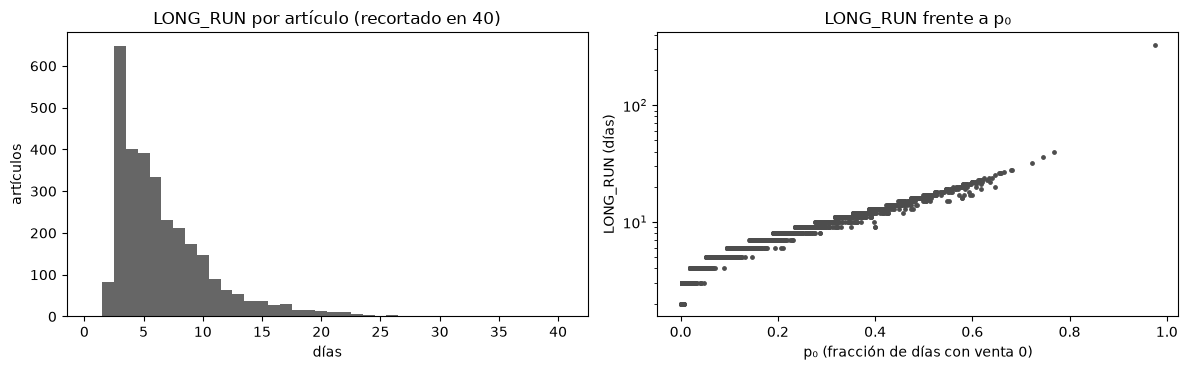

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
lr = thresholds["long_run"]
axes[0].hist(lr.clip(upper=40), bins=np.arange(1, 42) - 0.5, color="0.4")
axes[0].set(title="LONG_RUN por artículo (recortado en 40)", xlabel="días", ylabel="artículos")
est = thresholds[thresholds["source"] == "formula"]
axes[1].scatter(est["p0"], est["long_run"], s=6, color="0.3")
axes[1].set(title="LONG_RUN frente a p₀", xlabel="p₀ (fracción de días con venta 0)", ylabel="LONG_RUN (días)", yscale="log")
fig.tight_layout()
plt.show()

### 1.4 · Enmascarar quiebres

**Qué hace**, en tres pasos:
1. `find_zero_runs`: lista las rachas de ceros de la serie completa recortada (con `zero_runs` del módulo; los días NaN se saltan, así que una racha se mide en días con dato). Tras el recorte todas son internas.
2. `classify_runs`: cada racha con largo ≥ LONG_RUN del artículo es `break` (quiebre); las más cortas son `demand` (demanda real). Los umbrales de train se aplican también a Y5. Una racha que cruza d_1577 → d_1578 se mide entera.
3. `mask_breaks`: los ceros de las rachas `break` pasan a NaN; los de `demand` se quedan en 0.

**Entra:** `units_lc`, `thresholds`. **Sale:** `zero_runs_lc`, `zero_runs_kind` y `units_treated` (DataFrames).
**Revisar:** que todas las rachas sean internas y los conteos por tipo.

In [14]:
def find_zero_runs(units_lc):
    """Rachas de ceros de cada artículo con `zero_runs` del módulo (días base 1 como en el resto del proyecto)."""
    start_d, end_d = int(units_lc.columns[0][2:]), int(units_lc.columns[-1][2:])
    full = np.full((len(units_lc), end_d), np.nan)
    full[:, start_d - 1 :] = units_lc.to_numpy()
    return zero_runs({"item_ids": units_lc.index.to_numpy(dtype=object), "item_units": full}, start_d, end_d)


zero_runs_lc = find_zero_runs(units_lc)
assert (zero_runs_lc["position"] == "internal").all(), "tras el recorte no debe haber rachas de arranque ni finales"
print(f"rachas internas: {len(zero_runs_lc):,}")
display(zero_runs_lc.head())
display(zero_runs_lc["length"].describe(percentiles=[0.5, 0.9, 0.99]).to_frame("largo (días)").T)

rachas internas: 235,607


,item_id,position,start_d,end_d,length
0,FOODS_1_001,internal,189,189,1
1,FOODS_1_001,internal,192,270,79
2,FOODS_1_001,internal,273,276,4
3,FOODS_1_001,internal,331,331,1
4,FOODS_1_001,internal,697,697,1


,count,mean,std,min,50%,90%,99%,max
largo (días),235607.0,2.832114,10.920861,1.0,1.0,4.0,31.0,1249.0


In [15]:
def classify_runs(runs, long_run):
    """Etiqueta cada racha: `break` si su largo ≥ LONG_RUN del artículo, `demand` si es más corta."""
    out = runs.assign(long_run=runs["item_id"].map(long_run))
    out["kind"] = np.where(out["length"] >= out["long_run"], "break", "demand")
    return out


zero_runs_kind = classify_runs(zero_runs_lc, thresholds["long_run"])
assert zero_runs_kind["long_run"].notna().all()
display(zero_runs_kind.head())
display(zero_runs_kind.groupby("kind").agg(rachas=("length", "size"), días=("length", "sum"),
                                           largo_mediano=("length", "median"), largo_max=("length", "max")))

,item_id,position,start_d,end_d,length,long_run,kind
0,FOODS_1_001,internal,189,189,1,6,demand
1,FOODS_1_001,internal,192,270,79,6,break
2,FOODS_1_001,internal,273,276,4,6,demand
3,FOODS_1_001,internal,331,331,1,6,demand
4,FOODS_1_001,internal,697,697,1,6,demand


,rachas,días,largo_mediano,largo_max
kind,,,,
break,11762,302667,13.0,1249
demand,223845,364599,1.0,96


In [16]:
def mask_breaks(units_lc, runs_kind):
    """Copia de `units_lc` con los ceros de las rachas `break` en NaN."""
    out = units_lc.to_numpy(copy=True)
    start_d = int(units_lc.columns[0][2:])
    rows = units_lc.index.get_indexer(runs_kind["item_id"])
    breaks = (runs_kind["kind"] == "break").to_numpy()
    for r, a, b in zip(rows[breaks], runs_kind["start_d"].to_numpy()[breaks], runs_kind["end_d"].to_numpy()[breaks]):
        block = out[r, a - start_d : b - start_d + 1]
        block[block == 0] = np.nan
    return pd.DataFrame(out, index=units_lc.index, columns=units_lc.columns)


units_treated = mask_breaks(units_lc, zero_runs_kind)
print("units_treated:", units_treated.shape)
display(units_treated.iloc[:5, :8])

units_treated: (3049, 1820)


,d_122,d_123,d_124,d_125,d_126,d_127,d_128,d_129
item_id,,,,,,,,
FOODS_1_001,4.0,10.0,9.0,12.0,15.0,9.0,21.0,5.0
FOODS_1_002,2.0,1.0,1.0,4.0,8.0,3.0,0.0,7.0
FOODS_1_003,4.0,6.0,13.0,6.0,8.0,10.0,5.0,18.0
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.4 · Ceros por categoría

**Qué hace:** `zero_categories` compara la serie original, la recortada y la tratada, y clasifica cada día con cero en `lifecycle` (fuera del ciclo de vida), `demand` (racha corta, se queda en 0) o `break` (racha ≥ LONG_RUN, pasa a NaN).
**Entra:** `units`, `units_lc`, `units_treated`. **Sale:** `zero_cat` (DataFrame por artículo).
**Revisar:** que las tres categorías sumen todos los ceros, el reparto total y qué artículos acumulan más días de quiebre.

In [17]:
def zero_categories(units, units_lc, units_treated):
    """Días con cero de cada artículo por categoría: ciclo de vida, demanda real o quiebre."""
    zero = units == 0
    out = pd.DataFrame({
        "zero_days": zero.sum(axis=1),
        "lifecycle": (zero & units_lc.isna()).sum(axis=1),
        "demand": (units_treated == 0).sum(axis=1),
        "break": (zero & units_lc.notna() & units_treated.isna()).sum(axis=1),
    })
    out["active_days"] = units.notna().sum(axis=1)
    return out


zero_cat = zero_categories(units, units_lc, units_treated)
cats = ["lifecycle", "demand", "break"]
assert (zero_cat[cats].sum(axis=1) == zero_cat["zero_days"]).all()
tot = zero_cat[cats].sum()
display(pd.DataFrame({"días con cero": tot, "% de los ceros": tot / tot.sum() * 100,
                      "artículos con alguno": (zero_cat[cats] > 0).sum()}).round(2))
display(zero_cat.head(10))
display(zero_cat.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
display(zero_cat.sort_values("break", ascending=False).head(10).join(thresholds[["p0", "long_run"]]))

,días con cero,% de los ceros,artículos con alguno
lifecycle,16634,2.43,1479
demand,364599,53.31,3048
break,302667,44.26,2063


,zero_days,lifecycle,demand,break,active_days
item_id,,,,,
FOODS_1_001,188,0,37,151,1820
FOODS_1_002,76,0,76,0,1820
FOODS_1_003,31,0,31,0,1820
FOODS_1_004,149,4,14,131,1542
FOODS_1_005,436,84,107,245,1820
FOODS_1_006,10,0,10,0,1820
FOODS_1_008,410,4,181,225,1682
FOODS_1_009,508,1,86,421,1542
FOODS_1_010,262,4,235,23,1820


,zero_days,lifecycle,demand,break,active_days
count,3049.0,3049.0,3049.0,3049.0,3049.0
mean,224.3,5.5,119.6,99.3,1539.8
std,233.7,36.0,172.4,145.5,393.0
min,1.0,0.0,0.0,0.0,415.0
50%,144.0,0.0,48.0,32.0,1820.0
90%,561.2,6.0,349.2,301.2,1820.0
99%,979.5,100.0,846.6,644.0,1820.0
max,1423.0,1054.0,1127.0,1249.0,1820.0


,zero_days,lifecycle,demand,break,active_days,p0,long_run
item_id,,,,,,,
HOUSEHOLD_1_512,1423,8,166,1249,1820,0.975138,326
HOUSEHOLD_2_162,1405,1,186,1218,1820,0.577283,20
HOUSEHOLD_1_063,1281,0,298,983,1820,0.768698,40
HOBBIES_1_335,1014,4,104,906,1430,0.588360,20
HOUSEHOLD_2_420,931,0,96,835,1820,0.515110,17
HOUSEHOLD_2_116,994,0,183,811,1820,0.556319,19
HOUSEHOLD_2_502,1162,0,352,810,1820,0.679945,28
HOUSEHOLD_2_449,907,0,97,810,1820,0.517170,17
FOODS_2_221,893,0,92,801,1820,0.598901,22


## Etapa 2 · Partición

**Qué hace:** `split_days` recorta un DataFrame artículo × día a un rango de días. Se llama una vez por partición y por versión de la serie: train = Y1–Y4 (d_122–d_1577) y test = Y5 (d_1578–d_1941). Las versiones son la original (`units`), la recortada al ciclo de vida (`units_lc`), la tratada (`units_treated`) y el gasto (`spend`). `partition_summary` resume cada partición con sus fechas.
**Entra:** las series de la Etapa 1 y el calendario. **Sale:** `train` y `test` (dicts de DataFrames) y `partitions` (tabla).
**Revisar:** fechas de corte, 1,456 + 364 = 1,820 días, artículos con ciclo de vida en cada partición y el reparto de ceros por categoría en cada una.

In [18]:
from src.data import load_calendar


def split_days(df, start_d, end_d):
    """Columnas d_start_d … d_end_d de un DataFrame artículo × día."""
    return df.loc[:, f"d_{start_d}" : f"d_{end_d}"]


SERIES = {"units": units, "units_lc": units_lc, "units_treated": units_treated, "spend": spend}
train = {name: split_days(df, START_D, TRAIN_END) for name, df in SERIES.items()}
test = {name: split_days(df, TEST_START, END_D) for name, df in SERIES.items()}
display(pd.DataFrame({"train": {k: v.shape for k, v in train.items()}, "test": {k: v.shape for k, v in test.items()}}))

,train,test
units,"(3049, 1456)","(3049, 364)"
units_lc,"(3049, 1456)","(3049, 364)"
units_treated,"(3049, 1456)","(3049, 364)"
spend,"(3049, 1456)","(3049, 364)"


In [19]:
def partition_summary(parts, calendar):
    """Fechas, días y artículos con dato / con ciclo de vida de cada partición."""
    date = calendar.set_index("d")["date"]
    rows = {}
    for name, p in parts.items():
        first, last = p["units"].columns[0], p["units"].columns[-1]
        rows[name] = {
            "start_d": first, "end_d": last, "start_date": date[first], "end_date": date[last],
            "days": p["units"].shape[1],
            "items_with_data": int(p["units"].notna().any(axis=1).sum()),
            "items_in_lifecycle": int(p["units_lc"].notna().any(axis=1).sum()),
            "units": p["units"].sum().sum(), "spend": p["spend"].sum().sum(),
        }
    return pd.DataFrame(rows).T


calendar = load_calendar(cfg)
partitions = partition_summary({"train": train, "test": test}, calendar)
assert partitions["days"].sum() == units.shape[1]
display(partitions)

,start_d,end_d,start_date,end_date,days,items_with_data,items_in_lifecycle,units,spend
train,d_122,d_1577,2011-05-30,2015-05-24,1456,3049,3049,49385491.0,138428503.799223
test,d_1578,d_1941,2015-05-25,2016-05-22,364,3049,3049,14548395.0,45041697.875872


In [20]:
zero_cat_split = pd.concat({
    name: zero_categories(p["units"], p["units_lc"], p["units_treated"])[cats].sum()
    for name, p in {"train": train, "test": test}.items()
}, axis=1).T
zero_cat_split["total"] = zero_cat_split.sum(axis=1)
assert (zero_cat_split[cats].sum() == zero_cat[cats].sum()).all()
display(zero_cat_split)
display((zero_cat_split[cats].div(zero_cat_split["total"], axis=0) * 100).round(2).rename(columns=lambda c: f"% {c}"))

,lifecycle,demand,break,total
train,15797,289421,248875,554093
test,837,75178,53792,129807


,% lifecycle,% demand,% break
train,2.85,52.23,44.92
test,0.64,57.92,41.44


## Bloques de 28 días y mínimo de días observados (prepara la Etapa 4)

La demanda de un bloque será `nanmean` de sus días: unidades ÷ días observados, sin escalar a 28. Antes hay que fijar cuántos días observados necesita un bloque para ser válido. Ese mínimo m se estima con los datos de **train** y todavía **no se aplica**.

### Bloques

**Qué hace:** `block_calendar` numera los bloques de 28 días desde d_122 (52 en train, 13 en test) con sus fechas; `observed_days_by_block` cuenta los días con dato de cada artículo en cada bloque.
**Entra:** `train["units_treated"]`, `calendar`. **Sale:** `blocks_train` (tabla de bloques) y `observed_train` (artículo × bloque).
**Revisar:** que el "mes" de cada artículo es un bloque de 28 días, no un mes calendario.

In [21]:
def block_calendar(df, calendar):
    """Bloques consecutivos de 28 días de las columnas de `df`, con su primer y último día y fecha."""
    date = calendar.set_index("d")["date"]
    cols = df.columns
    rows = [{"block": k + 1, "start_d": cols[a], "end_d": cols[a + 27],
             "start_date": date[cols[a]], "end_date": date[cols[a + 27]]}
            for k, a in enumerate(range(0, len(cols) // 28 * 28, 28))]
    return pd.DataFrame(rows).set_index("block")


def observed_days_by_block(df):
    """Días con dato (no NaN) de cada artículo en cada bloque de 28 días."""
    n_blocks = df.shape[1] // 28
    obs = (~np.isnan(df.to_numpy()[:, : n_blocks * 28])).reshape(len(df), n_blocks, 28).sum(axis=2)
    return pd.DataFrame(obs, index=df.index, columns=pd.RangeIndex(1, n_blocks + 1, name="block"))


blocks_train = block_calendar(train["units_treated"], calendar)
display(blocks_train.head(), blocks_train.tail(2))
observed_train = observed_days_by_block(train["units_treated"])
display(observed_train.iloc[:5, :10])
display(pd.Series(observed_train.to_numpy().ravel()).value_counts().sort_index().rename("bloques").to_frame().T)

,start_d,end_d,start_date,end_date
block,,,,
1,d_122,d_149,2011-05-30,2011-06-26
2,d_150,d_177,2011-06-27,2011-07-24
3,d_178,d_205,2011-07-25,2011-08-21
4,d_206,d_233,2011-08-22,2011-09-18
5,d_234,d_261,2011-09-19,2011-10-16


,start_d,end_d,start_date,end_date
block,,,,
51,d_1522,d_1549,2015-03-30,2015-04-26
52,d_1550,d_1577,2015-04-27,2015-05-24


block,1,2,3,4,5,6,7,8,9,10
item_id,,,,,,,,,,
FOODS_1_001,28,28,14,0,0,19,28,28,28,28
FOODS_1_002,28,28,28,28,28,28,28,28,28,28
FOODS_1_003,28,28,28,28,28,28,28,28,28,28
FOODS_1_004,0,0,0,0,0,0,0,0,0,0
FOODS_1_005,0,0,0,28,28,28,28,28,28,28


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28
bloques,34102,1087,498,356,347,346,372,333,338,327,387,399,372,343,357,370,284,373,375,372,483,857,589,385,400,396,333,588,112779


### Bloques de referencia

**Qué hace:** `complete_blocks` toma los bloques de la serie tratada de train **sin ningún NaN** (28 días observados) y con promedio > 0. Su promedio diario es el valor real. Añade el tercil de p₀ del artículo (p₀ de la Etapa 1).
**Entra:** `train["units_treated"]`, `thresholds["p0"]`. **Sale:** `ref_blocks` (DataFrame: una fila por bloque con sus 28 días, `true_mean` y `p0_tercile`).
**Revisar:** cuántos bloques de referencia hay y cuántos caen en cada tercil.

In [22]:
def complete_blocks(df, p0):
    """Bloques de 28 días sin NaN y con promedio > 0, con su promedio real y el tercil de p₀ del artículo."""
    n_blocks = df.shape[1] // 28
    values = df.to_numpy()[:, : n_blocks * 28].reshape(len(df), n_blocks, 28)
    item = np.repeat(df.index.to_numpy(dtype=object), n_blocks)
    block = np.tile(np.arange(1, n_blocks + 1), len(df))
    values = values.reshape(-1, 28)
    keep = ~np.isnan(values).any(axis=1)
    keep[keep] = values[keep].mean(axis=1) > 0
    out = pd.DataFrame(values[keep], columns=[f"day_{j}" for j in range(1, 29)])
    out.insert(0, "block", block[keep])
    out.insert(0, "item_id", item[keep])
    out["true_mean"] = values[keep].mean(axis=1)
    tercile = pd.qcut(p0, 3, labels=["T1 (p₀ bajo)", "T2 (p₀ medio)", "T3 (p₀ alto)"])
    out["p0_tercile"] = out["item_id"].map(tercile).astype(str)
    return out


ref_blocks = complete_blocks(train["units_treated"], thresholds["p0"])
print(f"bloques de referencia: {len(ref_blocks):,} de {observed_train.size:,}")
display(ref_blocks.head())
display(pd.qcut(thresholds["p0"], 3).value_counts().sort_index().rename("artículos").to_frame())
display(ref_blocks.groupby("p0_tercile").agg(bloques=("true_mean", "size"), artículos=("item_id", "nunique"),
                                             promedio_real_mediano=("true_mean", "median")))

bloques de referencia: 112,775 de 158,548


,item_id,block,day_1,day_2,day_3,day_4,day_5,day_6,day_7,day_8,day_9,day_10,day_11,day_12,day_13,...,day_16,day_17,day_18,day_19,day_20,day_21,day_22,day_23,day_24,day_25,day_26,day_27,day_28,true_mean,p0_tercile
0,FOODS_1_001,1,4.0,10.0,9.0,12.0,15.0,9.0,21.0,5.0,6.0,8.0,15.0,10.0,14.0,...,9.0,12.0,10.0,11.0,13.0,12.0,9.0,5.0,3.0,8.0,9.0,4.0,12.0,9.785714,T2 (p₀ medio)
1,FOODS_1_001,2,12.0,17.0,9.0,3.0,12.0,16.0,9.0,12.0,3.0,9.0,14.0,8.0,15.0,...,9.0,8.0,12.0,7.0,5.0,3.0,5.0,4.0,10.0,4.0,12.0,17.0,11.0,9.178571,T2 (p₀ medio)
2,FOODS_1_001,7,11.0,13.0,16.0,2.0,9.0,10.0,15.0,9.0,14.0,4.0,5.0,7.0,3.0,...,5.0,11.0,8.0,5.0,5.0,20.0,13.0,10.0,9.0,9.0,9.0,8.0,20.0,9.500000,T2 (p₀ medio)
3,FOODS_1_001,8,8.0,8.0,22.0,12.0,16.0,13.0,23.0,4.0,10.0,13.0,19.0,13.0,11.0,...,22.0,7.0,13.0,8.0,7.0,3.0,9.0,12.0,7.0,9.0,17.0,7.0,11.0,11.178571,T2 (p₀ medio)
4,FOODS_1_001,9,3.0,3.0,10.0,10.0,4.0,6.0,20.0,9.0,16.0,5.0,3.0,5.0,11.0,...,7.0,13.0,9.0,8.0,10.0,9.0,8.0,7.0,12.0,4.0,13.0,10.0,8.0,8.750000,T2 (p₀ medio)


,artículos
p0,
"(-0.001, 0.0453]",1018
"(0.0453, 0.187]",1015
"(0.187, 0.975]",1016


,bloques,artículos,promedio_real_mediano
p0_tercile,,,
T1 (p₀ bajo),41761,1018,11.607143
T2 (p₀ medio),38872,1015,6.178571
T3 (p₀ alto),32142,1014,2.357143


### Simulación Monte Carlo

**Qué hace:** `simulate_block_error` repite 500 veces sobre cada bloque de referencia: ordena sus 28 días al azar y, para cada m entre 3 y 27, conserva los primeros m (equivale a ocultar al azar 28 − m días) y calcula |promedio con m días − promedio real| ÷ promedio real. Los errores se acumulan en un histograma fino (paso 0,001), del que salen la mediana y los cuartiles, en total y por tercil de p₀. Semilla fija (0).
**Entra:** `ref_blocks`. **Sale:** `block_error` (DataFrame: `group, m, p25, median, p75`).
**Revisar:** la curva del error mediano frente a m.
**Límite:** ocultar días al azar no reproduce los NaN reales, que vienen en rachas seguidas y pueden cortar semanas a medias (efecto día de la semana). El error real con huecos seguidos puede ser algo distinto al simulado.

In [23]:
def simulate_block_error(ref_blocks, m_values, n_rep, seed, bin_width=0.001, max_err=5.0):
    """Cuantiles del error relativo del promedio con m días al azar frente al promedio de 28 días."""
    values = ref_blocks[[f"day_{j}" for j in range(1, 29)]].to_numpy()
    true_mean = ref_blocks["true_mean"].to_numpy()[:, None]
    groups = ref_blocks["p0_tercile"].to_numpy()
    labels = sorted(set(groups))
    g_idx = np.searchsorted(labels, groups)[:, None]
    m_idx = np.asarray(m_values) - 1
    n_bins = int(max_err / bin_width) + 1
    hist = np.zeros((len(labels), len(m_values), n_bins), dtype=np.int64)
    rng = np.random.default_rng(seed)
    cell = (g_idx * len(m_values) + np.arange(len(m_values))[None, :]) * n_bins
    for _ in range(n_rep):
        perm = np.argsort(rng.random(values.shape), axis=1)
        means = np.cumsum(np.take_along_axis(values, perm, axis=1), axis=1)[:, m_idx] / np.asarray(m_values)
        err = np.abs(means / true_mean - 1)
        bins = np.minimum((err / bin_width).astype(np.int64), n_bins - 1)
        hist += np.bincount((cell + bins).ravel(), minlength=hist.size).reshape(hist.shape)
    rows = []
    for name, h in [("total", hist.sum(axis=0))] + list(zip(labels, hist)):
        cdf = np.cumsum(h, axis=1) / h.sum(axis=1, keepdims=True)
        for k, m in enumerate(m_values):
            q = {f"p{int(p * 100)}": (np.searchsorted(cdf[k], p) + 0.5) * bin_width for p in (0.25, 0.5, 0.75)}
            rows.append({"group": name, "m": m, "p25": q["p25"], "median": q["p50"], "p75": q["p75"]})
    return pd.DataFrame(rows)


M_VALUES = list(range(3, 28))
block_error = simulate_block_error(ref_blocks, M_VALUES, n_rep=500, seed=0)
display(block_error.pivot(index="m", columns="group", values="median").round(3).T)

m,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
group,,,,,,,,,,,,,,,,,,,,,,,,,
T1 (p₀ bajo),0.154,0.130,0.114,0.102,0.092,0.084,0.078,0.072,0.066,0.062,0.058,0.054,0.050,0.046,0.042,0.04,0.036,0.034,0.030,0.028,0.024,0.022,0.018,0.014,0.010
T2 (p₀ medio),0.190,0.162,0.142,0.126,0.114,0.104,0.096,0.088,0.082,0.076,0.072,0.066,0.062,0.058,0.054,0.05,0.046,0.042,0.038,0.034,0.030,0.028,0.022,0.018,0.012
T3 (p₀ alto),0.272,0.232,0.200,0.180,0.164,0.150,0.138,0.126,0.119,0.110,0.103,0.096,0.088,0.082,0.076,0.07,0.066,0.060,0.054,0.050,0.044,0.038,0.032,0.026,0.018
total,0.192,0.164,0.143,0.128,0.116,0.106,0.096,0.090,0.082,0.076,0.072,0.066,0.062,0.058,0.054,0.05,0.046,0.042,0.038,0.034,0.030,0.028,0.022,0.018,0.012


### Umbral propuesto

**Qué hace:** `min_observed_days` toma, por grupo, el menor m con error mediano ≤ 15 %. La gráfica muestra la mediana (línea) y el rango intercuartílico del total (banda).
**Entra:** `block_error`. **Sale:** `m_by_group` (Series) y `M_PROPOSED` (umbral del total).
**Revisar:** si los terciles de p₀ dan umbrales muy distintos al del total.

group,total,T1 (p₀ bajo),T2 (p₀ medio),T3 (p₀ alto)
m mínimo,5,4,5,9


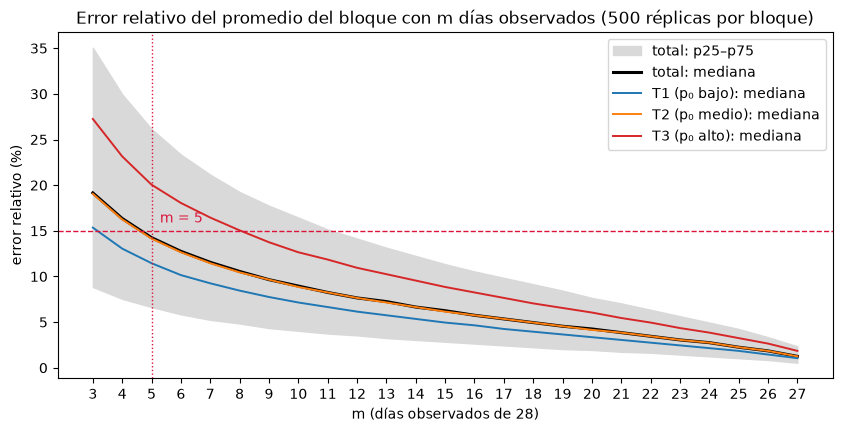

In [24]:
def min_observed_days(block_error, tol):
    """Menor m con error mediano ≤ `tol` en cada grupo (NaN si ningún m lo cumple)."""
    ok = block_error[block_error["median"] <= tol]
    return ok.groupby("group")["m"].min().reindex(block_error["group"].unique())


ERROR_TOL = 0.15
m_by_group = min_observed_days(block_error, ERROR_TOL)
M_PROPOSED = int(m_by_group["total"])
display(m_by_group.rename("m mínimo").to_frame().T)

fig, ax = plt.subplots(figsize=(10, 4.5))
tot = block_error[block_error["group"] == "total"]
ax.fill_between(tot["m"], tot["p25"] * 100, tot["p75"] * 100, color="0.85", label="total: p25–p75")
ax.plot(tot["m"], tot["median"] * 100, color="black", linewidth=2.2, label="total: mediana")
for (name, g), color in zip(block_error[block_error["group"] != "total"].groupby("group"), ["#1f77b4", "#ff7f0e", "#d62728"]):
    ax.plot(g["m"], g["median"] * 100, color=color, linewidth=1.4, label=f"{name}: mediana")
ax.axhline(ERROR_TOL * 100, color="crimson", linestyle="--", linewidth=1)
ax.axvline(M_PROPOSED, color="crimson", linestyle=":", linewidth=1)
ax.annotate(f"m = {M_PROPOSED}", (M_PROPOSED, ERROR_TOL * 100), xytext=(6, 6), textcoords="offset points", color="crimson")
ax.set(title="Error relativo del promedio del bloque con m días observados (500 réplicas por bloque)",
       xlabel="m (días observados de 28)", ylabel="error relativo (%)", xticks=M_VALUES)
ax.legend()
plt.show()

### Umbral aplicado: m por tercil de p₀

**Decisión:** se usa el m de cada tercil (no el global): cada artículo recibe el m de su tercil de p₀. Los límites de los terciles y los tres m salen de train y se congelan para test, igual que LONG_RUN.
**Qué hace:** `item_min_days` asigna a cada artículo su tercil y su m.
**Entra:** `thresholds["p0"]`, `m_by_group`. **Sale:** `min_days` (DataFrame: `p0, p0_tercile, min_days`) y `p0_tercile_edges`.
**Revisar:** artículos por tercil y su m.

In [25]:
def item_min_days(p0, m_by_group):
    """Tercil de p₀ de cada artículo y el mínimo de días observados de ese tercil."""
    tercile, edges = pd.qcut(p0, 3, labels=["T1 (p₀ bajo)", "T2 (p₀ medio)", "T3 (p₀ alto)"], retbins=True)
    out = pd.DataFrame({"p0": p0, "p0_tercile": tercile.astype(str)})
    out["min_days"] = out["p0_tercile"].map(m_by_group).astype(int)
    return out, edges


min_days, p0_tercile_edges = item_min_days(thresholds["p0"], m_by_group)
print("límites de los terciles de p₀:", np.round(p0_tercile_edges, 4))
display(min_days.head())
display(min_days.groupby(["p0_tercile", "min_days"]).size().rename("artículos").to_frame())

límites de los terciles de p₀: [0.     0.0453 0.1868 0.9751]


,p0,p0_tercile,min_days
item_id,,,
FOODS_1_001,0.122940,T2 (p₀ medio),5
FOODS_1_002,0.039148,T1 (p₀ bajo),4
FOODS_1_003,0.015110,T1 (p₀ bajo),4
FOODS_1_004,0.060477,T2 (p₀ medio),5
FOODS_1_005,0.255831,T3 (p₀ alto),9


,,artículos
p0_tercile,min_days,
T1 (p₀ bajo),4,1018
T2 (p₀ medio),5,1015
T3 (p₀ alto),9,1016


### Bloques inválidos con m por tercil

**Qué hace:** `block_validity` clasifica cada bloque artículo × bloque en `empty` (0 días observados: fuera del ciclo de vida o cubierto por un quiebre), `invalid` (1 a m − 1 días, con el m del artículo) o `valid` (≥ m). Se cuenta para la serie cruda (`units_lc`: ciclo de vida con los quiebres en 0) y la limpia (`units_treated`), en train y en test, y se compara con el m global.
**Entra:** las series de la Etapa 2, `min_days`. **Sale:** `validity` (tabla) y `validity_by_tercile` (train limpio por tercil).
**Revisar:** cuántos bloques quedan inválidos y cuántos artículos se quedan con menos de 2 bloques válidos (CV indefinido).

In [26]:
def block_validity(observed, m):
    """Conteo de bloques vacíos, inválidos (< m días) y válidos (≥ m días), y artículos con < 2 válidos.

    `m` es un entero o una Series item_id → m alineable con las filas de `observed`.
    """
    obs = observed.to_numpy()
    if isinstance(m, pd.Series):
        m = m.reindex(observed.index).to_numpy()[:, None]
    valid_per_item = (obs >= m).sum(axis=1)
    return pd.Series({
        "bloques": obs.size,
        "empty": int((obs == 0).sum()),
        "invalid": int(((obs > 0) & (obs < m)).sum()),
        "valid": int((obs >= m).sum()),
        "% invalid (sobre no vacíos)": ((obs > 0) & (obs < m)).sum() / (obs > 0).sum() * 100,
        "artículos con < 2 bloques válidos": int((valid_per_item < 2).sum()),
    })


observed = {(part, version): observed_days_by_block(p[series])
            for part, p in {"train": train, "test": test}.items()
            for version, series in {"crudo": "units_lc", "limpio": "units_treated"}.items()}
validity = pd.concat({
    "m por tercil": pd.DataFrame({k: block_validity(obs, min_days["min_days"]) for k, obs in observed.items()}),
    f"m global = {M_PROPOSED}": pd.DataFrame({k: block_validity(obs, M_PROPOSED) for k, obs in observed.items()}),
})
display(validity.round(2))

obs_tl = observed[("train", "limpio")]
validity_by_tercile = pd.DataFrame({
    t: block_validity(obs_tl.loc[g.index], g["min_days"]) for t, g in min_days.groupby("p0_tercile")
})
display(validity_by_tercile.round(2))

train             \
                                                    crudo     limpio   
m por tercil bloques                            158548.00  158548.00   
             empty                               30372.00   34102.00   
             invalid                               272.00    3134.00   
             valid                              127904.00  121312.00   
             % invalid (sobre no vacíos)             0.21       2.52   
             artículos con < 2 bloques válidos       0.00       0.00   
m global = 5 bloques                            158548.00  158548.00   
             empty                               30372.00   34102.00   
             invalid                               204.00    2288.00   
             valid                              127972.00  122158.00   
             % invalid (sobre no vacíos)             0.16       1.84   
             artículos con < 2 bloques válidos       0.00       0.00   

                                                    test            
                                                   crudo    limpio  
m por tercil bloques                            39637.00  39637.00  
             empty                                 15.00    708.00  
             invalid                                4.00    662.00  
             valid                              39618.00  38267.00  
             % invalid (sobre no vacíos)            0.01      1.70  
             artículos con < 2 bloques válidos      0.00      1.00  
m global = 5 bloques                            39637.00  39637.00  
             empty                                 15.00    708.00  
             invalid                                1.00    560.00  
             valid                              39621.00  38369.00  
             % invalid (sobre no vacíos)            0.00      1.44  
             artículos con < 2 bloques válidos      0.00      1.00

,T1 (p₀ bajo),T2 (p₀ medio),T3 (p₀ alto)
bloques,52936.00,52780.00,52832.0
empty,10014.00,9461.00,14627.0
invalid,56.00,708.00,2370.0
valid,42866.00,42611.00,35835.0
% invalid (sobre no vacíos),0.13,1.63,6.2
artículos con < 2 bloques válidos,0.00,0.00,0.0


# Sobre TRAIN

## Etapa 3 · ABC

### 3.1 · Gasto por bloque de 28 días

**Qué hace:** `block_sums` suma cada bloque de 28 días (el "mes") de un DataFrame artículo × día; un bloque sin ningún día con dato queda NaN. Se aplica al gasto y a las unidades de train (serie original: los ceros no aportan gasto, así que recortar o enmascarar no cambia el gasto).
**Entra:** `train["spend"]`, `train["units"]`. **Sale:** `spend_blocks_train`, `units_blocks_train` (artículo × bloque, 52 bloques).
**Revisar:** que el total por bloques coincida con el total diario (1,456 días = 52 × 28, no sobra ningún día).

In [27]:
def block_sums(df):
    """Suma por bloque de 28 días de un DataFrame artículo × día (NaN si el bloque no tiene datos)."""
    n_blocks = df.shape[1] // 28
    arr = df.to_numpy()[:, : n_blocks * 28].reshape(len(df), n_blocks, 28)
    sums = np.where(np.isnan(arr).all(axis=2), np.nan, np.nansum(arr, axis=2))
    return pd.DataFrame(sums, index=df.index, columns=pd.RangeIndex(1, n_blocks + 1, name="block"))


spend_blocks_train = block_sums(train["spend"])
units_blocks_train = block_sums(train["units"])
assert np.isclose(np.nansum(spend_blocks_train.to_numpy()), np.nansum(train["spend"].to_numpy()))
print("spend_blocks_train:", spend_blocks_train.shape)
display(spend_blocks_train.iloc[:5, :8].round(1))
display(units_blocks_train.iloc[:5, :8])

spend_blocks_train: (3049, 52)


block,1,2,3,4,5,6,7,8
item_id,,,,,,,,
FOODS_1_001,548.0,514.0,202.0,0.0,0.0,280.5,532.0,626.0
FOODS_1_002,782.9,806.6,814.0,917.3,781.8,852.5,976.8,902.5
FOODS_1_003,835.2,613.4,642.2,498.2,714.2,590.4,702.7,682.6
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,0.0,0.0,0.0,1895.1,2656.8,2053.3,1790.9,1699.0


block,1,2,3,4,5,6,7,8
item_id,,,,,,,,
FOODS_1_001,274.0,257.0,101.0,0.0,0.0,141.0,266.0,313.0
FOODS_1_002,99.0,102.0,103.0,116.0,95.0,96.0,110.0,102.0
FOODS_1_003,290.0,213.0,223.0,173.0,248.0,205.0,244.0,237.0
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,0.0,0.0,0.0,578.0,810.0,626.0,546.0,518.0


### 3.2 · Gasto por artículo y ranking acumulado

**Qué hace:** `spend_by_item` suma los bloques de cada artículo; `rank_cumulative` lo ordena de mayor a menor (empates por `item_id`) y calcula el gasto acumulado, el % acumulado (`cum_pct`), el % acumulado antes de sumar el artículo (`cum_pct_before`, el que usa la clasificación) y el % acumulado de artículos.
**Entra:** `spend_blocks_train`. **Sale:** `spend_item_train` (Series) y `ranked_train` (DataFrame).
**Revisar:** gasto total, artículos con gasto 0 y la forma de la curva.

In [28]:
def spend_by_item(blocks):
    """Gasto total de cada artículo sumando sus bloques."""
    return blocks.sum(axis=1, min_count=1).fillna(0).rename("spend")


def rank_cumulative(spend):
    """Artículos ordenados por gasto descendente con gasto acumulado y porcentajes acumulados."""
    out = spend.rename_axis("item_id").reset_index().sort_values(["spend", "item_id"], ascending=[False, True], kind="stable")
    out = out.reset_index(drop=True)
    total = out["spend"].sum()
    out["rank"] = np.arange(1, len(out) + 1)
    out["cum_spend"] = out["spend"].cumsum()
    out["cum_pct"] = out["cum_spend"] / total
    out["cum_pct_before"] = (out["cum_spend"] - out["spend"]) / total
    out["share"] = out["spend"] / total
    out["cum_items_pct"] = out["rank"] / len(out)
    return out


spend_item_train = spend_by_item(spend_blocks_train)
display(spend_item_train.describe().to_frame().T.round(1))
print(f"gasto total de train: {spend_item_train.sum():,.0f} · artículos con gasto 0: {(spend_item_train == 0).sum()}")
ranked_train = rank_cumulative(spend_item_train)
display(ranked_train.head(), ranked_train.tail(3))

,count,mean,std,min,25%,50%,75%,max
spend,3049.0,45401.3,70718.8,111.3,11502.0,25378.0,50295.4,1119133.6


gasto total de train: 138,428,504 · artículos con gasto 0: 0


,item_id,spend,rank,cum_spend,cum_pct,cum_pct_before,share,cum_items_pct
0,FOODS_3_586,1.119134e+06,1,1.119134e+06,0.008085,0.000000,0.008085,0.000328
1,FOODS_3_090,1.107543e+06,2,2.226676e+06,0.016085,0.008085,0.008001,0.000656
2,FOODS_3_120,9.797473e+05,3,3.206423e+06,0.023163,0.016085,0.007078,0.000984
3,FOODS_3_202,9.447823e+05,4,4.151206e+06,0.029988,0.023163,0.006825,0.001312
4,FOODS_3_587,6.689146e+05,5,4.820120e+06,0.034820,0.029988,0.004832,0.001640


,item_id,spend,rank,cum_spend,cum_pct,cum_pct_before,share,cum_items_pct
3046,HOBBIES_2_025,223.500000,3047,1.384283e+08,0.999998,0.999997,1.614552e-06,0.999344
3047,HOUSEHOLD_1_512,130.900001,3048,1.384284e+08,0.999999,0.999998,9.456145e-07,0.999672
3048,HOBBIES_2_026,111.320001,3049,1.384285e+08,1.000000,0.999999,8.041696e-07,1.000000


### 3.3 · Cortes ABC

**Qué hace:** `select_abc_cuts` (del módulo) recorre una grilla de pares (`cut_A` < `cut_B`, paso 0,01) y elige el que menos viola la regla de la config: A con 10–20 % de los artículos y 60–80 % del gasto; B con 20–30 % y 20–30 %. Desempate: más cerca del centro de los intervalos y después cortes más bajos. Devuelve también las fronteras de participación (`share_bounds`), que son las que se congelarán para test.
**Entra:** `spend_item_train`, `[segmentation]` de la config. **Sale:** `abc_rule` (dict: `cuts`, `share_bounds`, `scenarios`).
**Revisar:** los 10 mejores escenarios, que el elegido tenga violación 0 y sus fronteras de participación.

In [29]:
from src.segmentation import abc_rule_kwargs, select_abc_cuts

rule_kwargs = abc_rule_kwargs(cfg["segmentation"])
display(pd.Series(rule_kwargs, name="regla ABC").to_frame())
abc_rule = select_abc_cuts(spend_item_train.index, spend_item_train.to_numpy(), **rule_kwargs)
print("cortes elegidos (cum_pct_before):", abc_rule["cuts"])
print("fronteras de participación A, B:", [f"{b:.6%}" for b in abc_rule["share_bounds"]])
display(abc_rule["scenarios"].head(10).round(2))

,regla ABC
item_bounds,"[(0.1, 0.2), (0.2, 0.3)]"
spend_bounds,"[(0.6, 0.8), (0.2, 0.3)]"
step,0.01


cortes elegidos (cum_pct_before): [0.6, 0.84]
fronteras de participación A, B: ['0.044913%', '0.020602%']


,cut_A,cut_B,A_items_pct,A_spend_pct,B_items_pct,B_spend_pct,C_items_pct,C_spend_pct,violation,center_distance
0,0.60,0.84,19.45,60.03,26.07,23.99,54.48,15.98,0.00,16.50
1,0.60,0.83,19.45,60.03,24.50,22.98,56.05,16.99,0.00,16.94
2,0.60,0.85,19.45,60.03,27.68,24.98,52.87,14.99,0.00,17.12
3,0.60,0.82,19.45,60.03,22.99,21.97,57.56,17.99,0.00,19.45
4,0.60,0.86,19.45,60.03,29.39,25.98,51.16,13.99,0.00,19.78
5,0.60,0.81,19.45,60.03,21.55,20.97,59.00,18.99,0.00,21.89
6,0.60,0.80,19.45,60.03,20.14,19.97,60.41,20.00,0.03,24.31
7,0.61,0.84,20.17,61.01,25.35,23.01,54.48,15.98,0.17,16.50
8,0.61,0.85,20.17,61.01,26.96,24.00,52.87,14.99,0.17,17.12
9,0.61,0.86,20.17,61.01,28.67,25.00,51.16,13.99,0.17,17.83


### 3.4 · Clases ABC

**Qué hace:** `assign_abc` marca A si `cum_pct_before` < `cut_A`, B si < `cut_B` y C en otro caso (el artículo que cruza el corte queda en la clase superior).
**Entra:** `ranked_train`, `abc_rule["cuts"]`. **Sale:** `abc_train` (DataFrame) y `abc_summary_train` (artículos y gasto por clase).
**Revisar:** % de artículos y % de gasto de cada clase frente a la regla, y que coincida con la clasificación interna de `select_abc_cuts`.

In [30]:
def assign_abc(ranked, cuts):
    """Clase ABC por % acumulado antes de sumar el artículo."""
    out = ranked.copy()
    out["abc_class"] = np.select([out["cum_pct_before"] < cuts[0], out["cum_pct_before"] < cuts[1]], ["A", "B"], "C")
    return out


def class_summary(df, col):
    """Artículos y gasto por clase, con sus porcentajes."""
    out = df.groupby(col).agg(items=("item_id", "size"), spend=("spend", "sum"),
                              min_share=("share", "min"), max_share=("share", "max"))
    out["items_pct"] = out["items"] / out["items"].sum() * 100
    out["spend_pct"] = out["spend"] / out["spend"].sum() * 100
    return out[["items", "items_pct", "spend", "spend_pct", "min_share", "max_share"]]


abc_train = assign_abc(ranked_train, abc_rule["cuts"])
check = abc_rule["abc"].set_index("item_id")["abc_class"]
assert (abc_train.set_index("item_id")["abc_class"] == check.reindex(abc_train["item_id"])).all()
abc_summary_train = class_summary(abc_train, "abc_class")
display(abc_summary_train.style.format({"items_pct": "{:.2f}", "spend_pct": "{:.2f}", "spend": "{:,.0f}",
                                        "min_share": "{:.6%}", "max_share": "{:.6%}"}))

,items,items_pct,spend,spend_pct,min_share,max_share
abc_class,,,,,,
A,593,19.45,"83,103,747",60.03,0.044920%,0.808456%
B,795,26.07,"33,203,419",23.99,0.020608%,0.044905%
C,1661,54.48,"22,121,337",15.98,0.000080%,0.020597%


### 3.5 · Curva acumulada con los cortes

Barras: gasto anual promedio por artículo (gasto de train ÷ 4), coloreado por clase. Línea: gasto acumulado (eje derecho). Líneas horizontales: cortes `cut_A` y `cut_B`; verticales: dónde terminan A y B en el ranking.

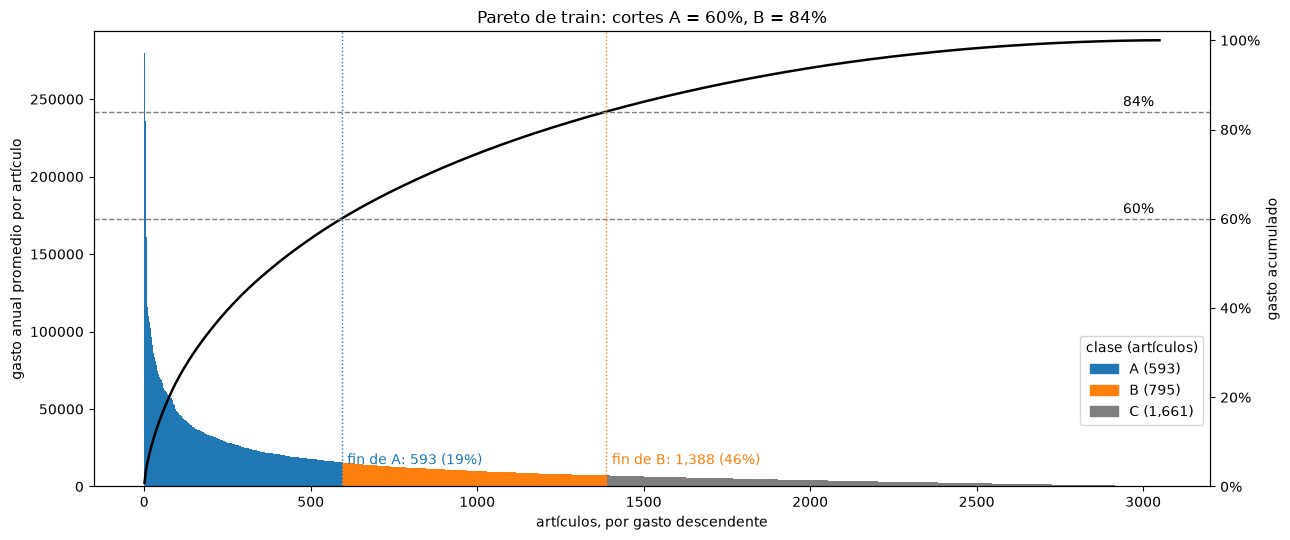

In [31]:
abc_colors = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#7f7f7f"}
n_train_years = 4
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(abc_train["rank"], abc_train["spend"] / n_train_years, width=1.0, color=abc_train["abc_class"].map(abc_colors), linewidth=0)
ax.set(title=f"Pareto de train: cortes A = {abc_rule['cuts'][0]:.0%}, B = {abc_rule['cuts'][1]:.0%}",
       xlabel="artículos, por gasto descendente", ylabel="gasto anual promedio por artículo")
ax.margins(x=0)
ax2 = ax.twinx()
ax2.plot(abc_train["rank"], abc_train["cum_pct"], color="black", linewidth=1.8)
for cut in abc_rule["cuts"]:
    ax2.axhline(cut, color="grey", linestyle="--", linewidth=1)
    ax2.annotate(f"{cut:.0%}", (len(abc_train), cut), xytext=(-4, 4), textcoords="offset points", ha="right")
for cls in ("A", "B"):
    last = abc_train.loc[abc_train["abc_class"] == cls, "rank"].max()
    ax2.axvline(last, color=abc_colors[cls], linestyle=":", linewidth=1)
    ax2.annotate(f"fin de {cls}: {last:,} ({last / len(abc_train):.0%})", (last, 0.05), xytext=(4, 0), textcoords="offset points", color=abc_colors[cls])
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax2.set(ylabel="gasto acumulado", ylim=(0, 1.02))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in abc_colors.values()]
ax.legend(handles, [f"{k} ({(abc_train['abc_class'] == k).sum():,})" for k in abc_colors], title="clase (artículos)", loc="lower right", bbox_to_anchor=(1, 0.12))
fig.tight_layout()
plt.show()

## Etapa 4 · CV crudo y CV limpio

El CV se calcula sobre la demanda diaria promedio de cada bloque de 28 días:

- **Demanda del bloque** = unidades ÷ días observados (`nanmean`): no se escala a 28, porque el CV no depende de la escala.
- **Bloque válido** si tiene al menos el m de su artículo (4 / 5 / 9 según el tercil de p₀); los inválidos y los vacíos no entran.
- **CV** = desviación estándar poblacional ÷ media × 100 sobre los bloques válidos. Queda indefinido con menos de 13 bloques válidos o con media 0. (La config trae `cv_min_blocks = 2`; se subió a 13 tras ver que los artículos con ≤ 12 bloques válidos son ~5 % y su CV es poco confiable.)

Dos versiones sobre train, con el mismo criterio:
- **Crudo:** `units_lc` (ciclo de vida recortado; los quiebres cuentan como 0).
- **Limpio:** `units_treated` (los quiebres son NaN y se descuentan de su bloque).

Los cortes XYZ **no** se calculan aquí: primero se miran las distribuciones (Etapa 5).

### 4.1 · Demanda promedio por bloque

**Qué hace:** `block_means` calcula el promedio diario de cada bloque con los días observados (NaN si el bloque no tiene ninguno).
**Entra:** `train["units_lc"]`, `train["units_treated"]`. **Sale:** `means_raw`, `means_clean` (artículo × bloque).
**Revisar:** que en los bloques sin NaN ambas versiones coincidan y que en los bloques con quiebre el limpio sea mayor (se descuentan los ceros del quiebre).

In [32]:
def block_means(df):
    """Promedio diario de cada bloque de 28 días con los días observados (NaN si no hay ninguno)."""
    n_blocks = df.shape[1] // 28
    arr = df.to_numpy()[:, : n_blocks * 28].reshape(len(df), n_blocks, 28)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        means = np.nanmean(arr, axis=2)
    return pd.DataFrame(means, index=df.index, columns=pd.RangeIndex(1, n_blocks + 1, name="block"))


means_raw = block_means(train["units_lc"])
means_clean = block_means(train["units_treated"])
display(means_raw.iloc[:5, :8].round(2), means_clean.iloc[:5, :8].round(2))

block,1,2,3,4,5,6,7,8
item_id,,,,,,,,
FOODS_1_001,9.79,9.18,3.61,0.00,0.00,5.04,9.50,11.18
FOODS_1_002,3.54,3.64,3.68,4.14,3.39,3.43,3.93,3.64
FOODS_1_003,10.36,7.61,7.96,6.18,8.86,7.32,8.71,8.46
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,NaN,NaN,NaN,20.64,28.93,22.36,19.50,18.50


block,1,2,3,4,5,6,7,8
item_id,,,,,,,,
FOODS_1_001,9.79,9.18,7.21,NaN,NaN,7.42,9.50,11.18
FOODS_1_002,3.54,3.64,3.68,4.14,3.39,3.43,3.93,3.64
FOODS_1_003,10.36,7.61,7.96,6.18,8.86,7.32,8.71,8.46
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,NaN,NaN,NaN,20.64,28.93,22.36,19.50,18.50


In [33]:
obs_raw, obs_clean = observed[("train", "crudo")], observed[("train", "limpio")]
both_full = (obs_raw == 28) & (obs_clean == 28)
full = both_full.to_numpy()
assert np.allclose(means_raw.to_numpy()[full], means_clean.to_numpy()[full])
with_break = (obs_clean < obs_raw) & (obs_clean > 0)
diff = pd.Series((means_clean - means_raw).to_numpy()[with_break.to_numpy()])
print(f"bloques con parte de quiebre: {with_break.to_numpy().sum():,} · limpio ≥ crudo en todos: {(diff >= 0).all()}")
display(diff.describe().to_frame("limpio − crudo (unidades/día)").T.round(3))

bloques con parte de quiebre: 10,368 · limpio ≥ crudo en todos: True


,count,mean,std,min,25%,50%,75%,max
limpio − crudo (unidades/día),10368.0,2.583,6.401,0.001,0.347,0.964,2.25,173.786


### 4.2 · Bloques válidos

**Qué hace:** `valid_block_means` deja en NaN los bloques con menos días observados que el m del artículo.
**Entra:** `means_*`, `observed` (días observados por bloque), `min_days`. **Sale:** `valid_raw`, `valid_clean` (artículo × bloque).
**Revisar:** bloques válidos por artículo en cada versión.

In [34]:
def valid_block_means(means, observed_days, min_days):
    """Promedios de bloque con NaN donde los días observados son menos que el m del artículo."""
    m = min_days.reindex(means.index).to_numpy()[:, None]
    return means.where(observed_days.to_numpy() >= m)


valid_raw = valid_block_means(means_raw, obs_raw, min_days["min_days"])
valid_clean = valid_block_means(means_clean, obs_clean, min_days["min_days"])
n_valid = pd.DataFrame({"crudo": valid_raw.notna().sum(axis=1), "limpio": valid_clean.notna().sum(axis=1)})
display(n_valid.describe().round(1).T)
print("bloques válidos en total:", n_valid.sum().to_dict())

,count,mean,std,min,25%,50%,75%,max
crudo,3049.0,41.9,13.9,2.0,32.0,52.0,52.0,52.0
limpio,3049.0,39.8,13.9,2.0,30.0,46.0,52.0,52.0


bloques válidos en total: {'crudo': 127904, 'limpio': 121312}


### 4.3 · CV por artículo

**Qué hace:** `cv_from_blocks` calcula, sobre los bloques válidos, el número de bloques, la media, la desviación estándar poblacional y el CV (%).
**Entra:** `valid_raw`, `valid_clean`, `CV_MIN_BLOCKS` = 13. **Sale:** `cv_raw`, `cv_clean` (DataFrames: `n_blocks, mean, std, cv`).
**Revisar:** artículos con CV indefinido y la distribución de cada versión.

In [35]:
def cv_from_blocks(valid_means, min_blocks):
    """CV (%) por artículo sobre sus bloques válidos; NaN con menos de `min_blocks` bloques o media 0."""
    arr = valid_means.to_numpy()
    n = (~np.isnan(arr)).sum(axis=1)
    with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean = np.nanmean(arr, axis=1)
        std = np.nanstd(arr, axis=1, ddof=0)
        cv = std / mean * 100
    cv = np.where((n >= min_blocks) & (mean > 0), cv, np.nan)
    return pd.DataFrame({"n_blocks": n, "mean": mean, "std": std, "cv": cv}, index=valid_means.index)


CV_MIN_BLOCKS = 13  # decisión de train: ≥ 13 bloques válidos (la config trae 2); con ≤ 12 el CV es poco confiable
cv_raw = cv_from_blocks(valid_raw, CV_MIN_BLOCKS)
display(cv_raw.head())

,n_blocks,mean,std,cv
item_id,,,,
FOODS_1_001,52,6.270604,2.880445,45.935690
FOODS_1_002,52,3.851648,0.492904,12.797226
FOODS_1_003,52,7.258242,1.683265,23.191080
FOODS_1_004,42,94.725798,33.499738,35.364958
FOODS_1_005,49,11.388484,7.750521,68.055775


In [36]:
cv_clean = cv_from_blocks(valid_clean, CV_MIN_BLOCKS)
display(cv_clean.head())

,n_blocks,mean,std,cv
item_id,,,,
FOODS_1_001,48,6.924447,2.253489,32.543957
FOODS_1_002,52,3.851648,0.492904,12.797226
FOODS_1_003,52,7.258242,1.683265,23.191080
FOODS_1_004,42,99.816409,30.956347,31.013285
FOODS_1_005,44,13.374310,7.127167,53.289982


### 4.4 · Crudo frente a limpio

**Qué hace:** `compare_cv` junta ambos CV por artículo con su diferencia y su tercil de p₀.
**Entra:** `cv_raw`, `cv_clean`, `min_days`. **Sale:** `cv_compare` (DataFrame).
**Revisar:** cuánto baja el CV al quitar los quiebres, en total y por tercil, y qué artículos cambian más.

In [37]:
def compare_cv(cv_raw, cv_clean, min_days):
    """CV crudo y limpio por artículo, su diferencia y el tercil de p₀."""
    out = pd.DataFrame({"cv_raw": cv_raw["cv"], "cv_clean": cv_clean["cv"],
                        "n_blocks_raw": cv_raw["n_blocks"], "n_blocks_clean": cv_clean["n_blocks"]})
    out["diff"] = out["cv_clean"] - out["cv_raw"]
    return out.join(min_days[["p0", "p0_tercile"]])


cv_compare = compare_cv(cv_raw, cv_clean, min_days)
print("CV indefinido:", cv_compare[["cv_raw", "cv_clean"]].isna().sum().to_dict())
display(cv_compare[["cv_raw", "cv_clean", "diff"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2))
display(cv_compare.groupby("p0_tercile")[["cv_raw", "cv_clean", "diff"]].median().round(2).rename(columns=lambda c: f"mediana {c}"))
print(f"artículos cuyo CV baja: {(cv_compare['diff'] < 0).sum():,} · sube: {(cv_compare['diff'] > 0).sum():,} · igual: {(cv_compare['diff'] == 0).sum():,}")
by_diff = cv_compare.dropna(subset=["diff"]).sort_values("diff")
display(by_diff.head(5), by_diff.tail(5))

CV indefinido: {'cv_raw': 139, 'cv_clean': 162}


,cv_raw,cv_clean,diff
count,2910.00,2887.00,2887.00
mean,42.19,33.88,-7.98
std,24.44,16.61,13.21
min,7.72,6.67,-98.43
10%,18.22,17.31,-25.78
25%,24.82,22.40,-11.22
50%,36.49,30.14,-1.26
75%,53.60,41.14,0.00
90%,71.38,54.71,0.00
max,434.53,149.66,11.63


,mediana cv_raw,mediana cv_clean,mediana diff
p0_tercile,,,
T1 (p₀ bajo),23.42,23.02,0.00
T2 (p₀ medio),38.25,31.02,-3.88
T3 (p₀ alto),59.73,39.31,-14.46


artículos cuyo CV baja: 1,810 · sube: 77 · igual: 1,000


,cv_raw,cv_clean,n_blocks_raw,n_blocks_clean,diff,p0,p0_tercile
item_id,,,,,,,
HOUSEHOLD_2_162,173.114493,74.689100,52,21,-98.425393,0.577283,T3 (p₀ alto)
FOODS_3_618,143.070297,46.577739,35,15,-96.492557,0.534884,T3 (p₀ alto)
HOUSEHOLD_1_063,188.982334,96.347807,52,22,-92.634527,0.768698,T3 (p₀ alto)
HOUSEHOLD_1_317,126.606128,35.875636,30,13,-90.730493,0.570388,T3 (p₀ alto)
FOODS_3_315,120.318490,34.024395,45,20,-86.294096,0.566828,T3 (p₀ alto)


,cv_raw,cv_clean,n_blocks_raw,n_blocks_clean,diff,p0,p0_tercile
item_id,,,,,,,
HOUSEHOLD_1_351,25.029739,28.550342,39,39,3.520602,0.014679,T1 (p₀ bajo)
FOODS_3_084,54.387084,58.412581,19,19,4.025497,0.070746,T2 (p₀ medio)
FOODS_3_733,49.891925,54.560112,18,18,4.668186,0.048000,T2 (p₀ medio)
FOODS_3_313,81.638334,91.510404,50,50,9.872070,0.012848,T1 (p₀ bajo)
FOODS_3_069,133.853639,145.480569,52,52,11.626931,0.037088,T1 (p₀ bajo)


In [38]:
few = pd.DataFrame({
    v: pd.cut(cv_compare[f"n_blocks_{v}"], [1, 2, 3, 5, 12, 25, 52], labels=["2", "3", "4–5", "6–12", "13–25", "26–52"]).value_counts().sort_index()
    for v in ("raw", "clean")
})
display(few.rename_axis("bloques válidos").rename(columns={"raw": "artículos (crudo)", "clean": "artículos (limpio)"}))
display(cv_compare.sort_values("cv_clean").head(5))

,artículos (crudo),artículos (limpio)
bloques válidos,,
2,1,5
3,0,7
4–5,28,23
6–12,110,127
13–25,376,423
26–52,2534,2464


,cv_raw,cv_clean,n_blocks_raw,n_blocks_clean,diff,p0,p0_tercile
item_id,,,,,,,
HOBBIES_1_228,7.721891,6.673939,49,49,-1.047952,0.013120,T1 (p₀ bajo)
HOUSEHOLD_1_330,41.348101,7.847332,16,14,-33.500769,0.160714,T2 (p₀ medio)
FOODS_3_473,7.985999,7.985999,52,52,0.000000,0.002747,T1 (p₀ bajo)
HOUSEHOLD_1_429,9.594250,8.193482,16,16,-1.400768,0.011390,T1 (p₀ bajo)
HOBBIES_1_179,8.969375,8.723270,49,49,-0.246104,0.013158,T1 (p₀ bajo)


### 4.5 · Artículos sin CV (menos de 13 bloques válidos)

**Qué hace:** `cv_exclusions` lista los artículos con CV indefinido en cada versión, con sus bloques válidos, su clase ABC y su participación en el gasto. Se quedan con su clase ABC pero sin clase XYZ.
**Entra:** `cv_compare`, `abc_train`. **Sale:** `cv_excluded` (DataFrame).
**Revisar:** cuántos artículos y qué parte del gasto quedan fuera de XYZ.

In [39]:
def cv_exclusions(cv_compare, abc):
    """Artículos con CV indefinido en alguna versión, con su ABC y su participación en el gasto."""
    out = cv_compare[cv_compare["cv_raw"].isna() | cv_compare["cv_clean"].isna()]
    out = out[["n_blocks_raw", "n_blocks_clean", "cv_raw", "cv_clean", "p0_tercile"]]
    out = out.join(abc.set_index("item_id")[["abc_class", "spend", "share"]])
    out["undefined_in"] = np.select([out["cv_raw"].isna() & out["cv_clean"].isna(), out["cv_clean"].isna()],
                                    ["ambos", "solo limpio"], "solo crudo")
    return out


cv_excluded = cv_exclusions(cv_compare, abc_train)
display(cv_excluded.groupby("undefined_in").agg(artículos=("spend", "size"), gasto_pct=("share", lambda s: s.sum() * 100)).round(2))
display(pd.crosstab(cv_excluded["abc_class"], cv_excluded["undefined_in"], margins=True))
excl = pd.Series({v: cv_compare[f"cv_{v}"].isna().sum() for v in ("raw", "clean")})
display(pd.DataFrame({"artículos sin CV": excl, "% de artículos": excl / len(cv_compare) * 100,
                      "% del gasto": [abc_train.set_index("item_id").loc[cv_compare.index[cv_compare[f"cv_{v}"].isna()], "share"].sum() * 100 for v in ("raw", "clean")]}).round(2))
display(cv_excluded.sort_values("spend", ascending=False).head(10))

,artículos,gasto_pct
undefined_in,,
ambos,139,0.52
solo limpio,23,0.26


undefined_in,ambos,solo limpio,All
abc_class,,,
A,0,1,1
C,139,22,161
All,139,23,162


,artículos sin CV,% de artículos,% del gasto
raw,139,4.56,0.52
clean,162,5.31,0.79


,n_blocks_raw,n_blocks_clean,cv_raw,cv_clean,p0_tercile,abc_class,spend,share,undefined_in
item_id,,,,,,,,,
HOBBIES_1_354,18,11,128.981416,NaN,T3 (p₀ alto),A,212995.376408,0.001539,solo limpio
FOODS_3_760,6,6,NaN,NaN,T1 (p₀ bajo),C,21158.460763,0.000153,ambos
HOUSEHOLD_1_049,16,12,96.753273,NaN,T3 (p₀ alto),C,20897.589375,0.000151,solo limpio
HOUSEHOLD_2_044,10,10,NaN,NaN,T1 (p₀ bajo),C,18920.760301,0.000137,ambos
FOODS_2_191,11,10,NaN,NaN,T3 (p₀ alto),C,17651.540098,0.000128,ambos
FOODS_2_346,11,11,NaN,NaN,T3 (p₀ alto),C,15446.000583,0.000112,ambos
FOODS_2_210,12,12,NaN,NaN,T1 (p₀ bajo),C,14745.900164,0.000107,ambos
FOODS_3_125,11,11,NaN,NaN,T2 (p₀ medio),C,14496.780106,0.000105,ambos
FOODS_2_387,12,12,NaN,NaN,T2 (p₀ medio),C,13981.660233,0.000101,ambos


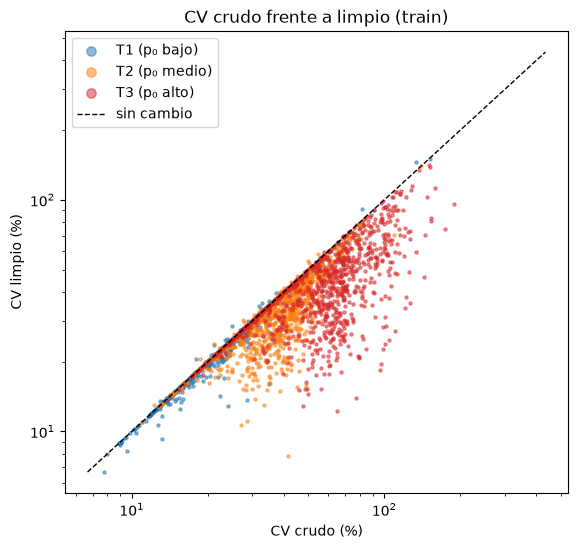

In [40]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for (t, g), color in zip(cv_compare.groupby("p0_tercile"), ["#1f77b4", "#ff7f0e", "#d62728"]):
    ax.scatter(g["cv_raw"], g["cv_clean"], s=5, alpha=0.5, color=color, label=t)
lims = [cv_compare[["cv_raw", "cv_clean"]].min().min(), cv_compare[["cv_raw", "cv_clean"]].max().max()]
ax.plot(lims, lims, color="black", linewidth=1, linestyle="--", label="sin cambio")
ax.set(xscale="log", yscale="log", xlabel="CV crudo (%)", ylabel="CV limpio (%)", title="CV crudo frente a limpio (train)")
ax.legend(markerscale=3)
plt.show()

## Etapa 5 · Distribuciones del CV

**Qué hace:** `cv_distribution_stats` resume la forma de cada distribución (percentiles y asimetría en escala original y en log); `plot_cv_distributions` dibuja el CV crudo y el limpio en escala original y logarítmica (2 × 2), con la mediana como referencia. Los cortes XYZ todavía no están definidos: sus líneas se añadirán aquí cuando se elija el criterio.
**Entra:** `cv_compare` (artículos con CV definido, ≥ 13 bloques válidos). **Sale:** `cv_stats` (tabla) y las figuras.
**Revisar:** cuánto se comprime la cola derecha al quitar los quiebres, si la escala log deja la distribución más simétrica y si se ve alguna separación natural (valles o modas) que sugiera dónde cortar.

In [41]:
def cv_distribution_stats(cvs):
    """Percentiles y asimetría de cada CV, en escala original y en log."""
    rows = {}
    for name, cv in cvs.items():
        cv = cv.dropna()
        q = cv.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
        rows[name] = {"artículos": len(cv), "min": cv.min(), "p5": q[0.05], "p25": q[0.25], "mediana": q[0.5],
                      "p75": q[0.75], "p95": q[0.95], "max": cv.max(), "asimetría": cv.skew(),
                      "asimetría log": np.log(cv).skew()}
    return pd.DataFrame(rows).T


CVS = {"crudo": cv_compare["cv_raw"], "limpio": cv_compare["cv_clean"]}
cv_stats = cv_distribution_stats(CVS)
display(cv_stats.round(2))

,artículos,min,p5,p25,mediana,p75,p95,max,asimetría,asimetría log
crudo,2910.0,7.72,15.40,24.82,36.49,53.60,88.33,434.53,2.67,0.06
limpio,2887.0,6.67,14.76,22.40,30.14,41.14,65.09,149.66,1.75,0.15


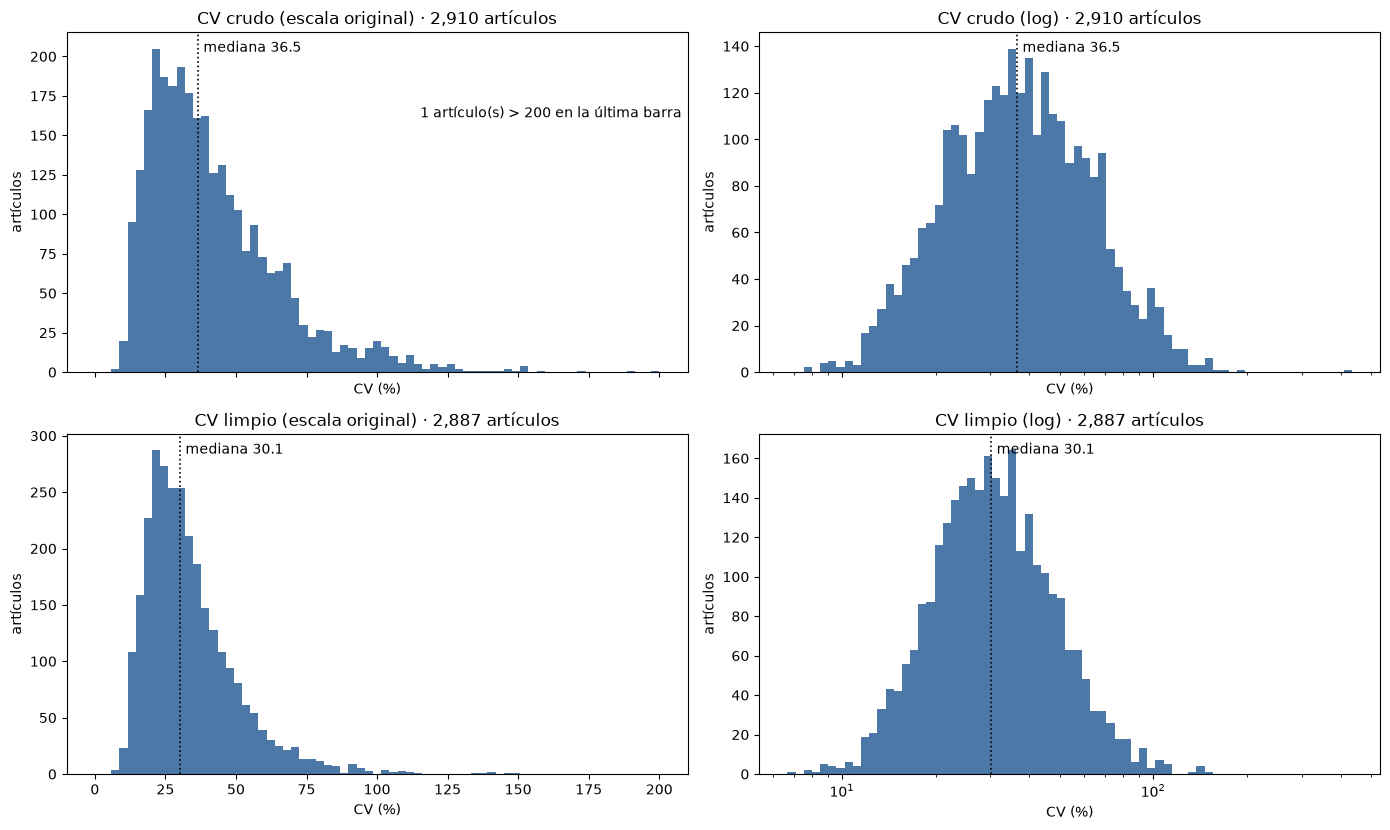

In [42]:
def plot_cv_distributions(cvs, cuts=None, bins=70):
    """CV de cada versión (filas) en escala original y log (columnas); `cuts` = {versión: [corte X, corte Z]}."""
    lo = min(cv.min() for cv in cvs.values())
    hi = max(cv.max() for cv in cvs.values())
    xmax = 200  # escala original: el eje se corta en 200 para que se vea la forma
    fig, axes = plt.subplots(len(cvs), 2, figsize=(14, 4.2 * len(cvs)), sharex="col")
    for row, (name, cv) in zip(axes, cvs.items()):
        cv = cv.dropna()
        for ax, log in zip(row, (False, True)):
            edges = np.logspace(np.log10(lo), np.log10(hi), bins) if log else np.linspace(0, xmax, bins)
            ax.hist(cv.clip(upper=None if log else xmax), bins=edges, color="#4c78a8")
            if log:
                ax.set_xscale("log")
            elif (cv > xmax).any():
                ax.annotate(f"{(cv > xmax).sum()} artículo(s) > {xmax:.0f} en la última barra", (1, 0.75),
                            xycoords="axes fraction", xytext=(-4, 0), textcoords="offset points", ha="right")
            ax.axvline(cv.median(), color="black", linestyle=":", linewidth=1.2)
            ax.annotate(f"mediana {cv.median():.1f}", (cv.median(), 1), xycoords=("data", "axes fraction"),
                        xytext=(4, -14), textcoords="offset points")
            for thr in (cuts or {}).get(name, []):
                ax.axvline(thr, color="crimson", linestyle="--", linewidth=1.3)
                ax.annotate(f"{thr:.1f}", (thr, 0.9), xycoords=("data", "axes fraction"), xytext=(4, -14),
                            textcoords="offset points", color="crimson")
            ax.set(title=f"CV {name} ({'log' if log else 'escala original'}) · {len(cv):,} artículos",
                   xlabel="CV (%)", ylabel="artículos")
    fig.tight_layout()
    return fig


fig = plot_cv_distributions(CVS)
plt.show()

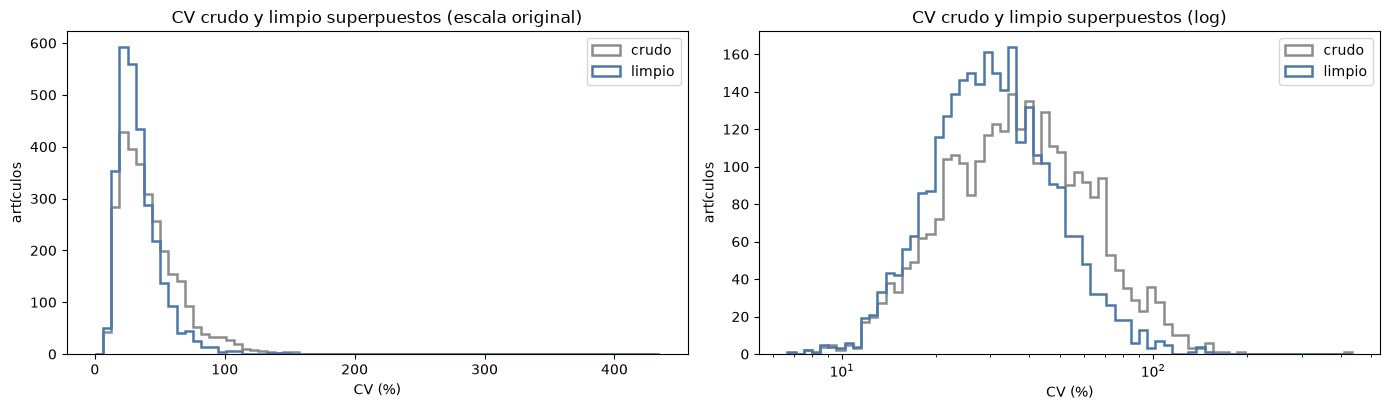

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
lo, hi = cv_stats["min"].min(), cv_stats["max"].max()
for ax, log in zip(axes, (False, True)):
    edges = np.logspace(np.log10(lo), np.log10(hi), 70) if log else np.linspace(0, hi, 70)
    for (name, cv), color in zip(CVS.items(), ["0.55", "#4c78a8"]):
        ax.hist(cv.dropna(), bins=edges, histtype="step", linewidth=1.8, color=color, label=name)
    if log:
        ax.set_xscale("log")
    ax.set(title=f"CV crudo y limpio superpuestos ({'log' if log else 'escala original'})", xlabel="CV (%)", ylabel="artículos")
    ax.legend()
fig.tight_layout()
plt.show()

## Etapa 4 (cont.) · Cortes XYZ con Jenks sobre log(CV)

**Criterio (decidido tras ver la Etapa 5):** cortes naturales de Jenks sobre log(CV).
1. Se ordenan los artículos por CV y se toma log(CV).
2. Para cada par de cortes candidato se forman 3 tramos seguidos (X = CV más bajo, Y = intermedio, Z = más alto) y se calcula la suma de cuadrados de log(CV) respecto a la media de su tramo (dispersión interna).
3. Gana el par con la menor dispersión interna, entre los que dejan al menos 20 % de los artículos en cada tramo. Búsqueda exhaustiva sobre 100 posiciones candidatas repartidas en la distribución; no se corta entre CV iguales.
4. Cada corte es el punto medio en log entre el último artículo de un tramo y el primero del siguiente, devuelto a % con la exponencial (equivale a la media geométrica de esos dos CV).

**Entra:** `cv_compare` (CV crudo y limpio, artículos con ≥ 13 bloques). **Sale:** `jenks_raw`, `jenks_clean` (dicts: `thresholds`, `log_thresholds`, `segments`, `gvf`, `n_evaluated`, `n_feasible`).
**Revisar:** los cortes en %, el tamaño de cada segmento y la bondad del ajuste (GVF = 1 − dispersión interna ÷ dispersión total; 1 = segmentos perfectamente compactos).
**Límite:** la distribución en log no tiene valles, así que los cortes son una partición convencional y dependen en buena parte del mínimo de 20 % por segmento.

In [44]:
from itertools import combinations


def jenks_cuts(cv, n_cuts=2, min_share=0.20, resolution=100, labels=("X", "Y", "Z")):
    """Cortes de Jenks sobre log(CV): mínima suma de cuadrados interna con ≥ `min_share` de artículos por tramo."""
    cv = cv.dropna().sort_values(kind="stable")
    x = np.log(cv.to_numpy())
    n = len(x)
    min_n = ceil(min_share * n)
    cands = np.flatnonzero(x[1:] > x[:-1]) + 1          # corte p = antes del artículo p; no entre empates
    cands = cands[(cands >= min_n) & (cands <= n - min_n)]
    if len(cands) > resolution:
        cands = cands[np.unique(np.linspace(0, len(cands) - 1, resolution).round().astype(int))]
    combos = np.array(list(combinations(cands, n_cuts)), dtype=np.int64)
    bounds = np.column_stack([np.zeros(len(combos), dtype=np.int64), combos, np.full(len(combos), n)])
    size = np.diff(bounds, axis=1)
    feasible = (size >= min_n).all(axis=1)
    s1, s2 = np.r_[0.0, np.cumsum(x)], np.r_[0.0, np.cumsum(x ** 2)]
    seg_sum, seg_sq = np.diff(s1[bounds], axis=1), np.diff(s2[bounds], axis=1)
    sse = (seg_sq - seg_sum ** 2 / size).sum(axis=1)
    sse[~feasible] = np.inf
    best = bounds[np.argmin(sse)]
    log_thr = [(x[p - 1] + x[p]) / 2 for p in best[1:-1]]
    sst = ((x - x.mean()) ** 2).sum()
    rows = []
    for label, a, b in zip(labels, best[:-1], best[1:]):
        seg = x[a:b]
        rows.append({"class": label, "n_items": int(b - a), "share_items": (b - a) / n,
                     "cv_min": float(np.exp(seg[0])), "cv_max": float(np.exp(seg[-1])),
                     "cv_median": float(np.exp(np.median(seg))), "cv_geo_mean": float(np.exp(seg.mean())),
                     "sse_log": float(((seg - seg.mean()) ** 2).sum())})
    return {"thresholds": [float(np.exp(t)) for t in log_thr], "log_thresholds": log_thr,
            "segments": pd.DataFrame(rows).set_index("class"), "gvf": 1 - sse.min() / sst,
            "n_evaluated": len(combos), "n_feasible": int(feasible.sum())}


jenks_raw = jenks_cuts(cv_compare["cv_raw"])
print(f"CRUDO · cortes (%): {[round(t, 2) for t in jenks_raw['thresholds']]} · log: {[round(t, 4) for t in jenks_raw['log_thresholds']]}")
print(f"particiones evaluadas: {jenks_raw['n_evaluated']:,} · factibles: {jenks_raw['n_feasible']:,} · GVF: {jenks_raw['gvf']:.3f}")
display(jenks_raw["segments"].round(3))

CRUDO · cortes (%): [26.64, 50.28] · log: [np.float64(3.2823), np.float64(3.9177)]
particiones evaluadas: 4,950 · factibles: 2,278 · GVF: 0.828


,n_items,share_items,cv_min,cv_max,cv_median,cv_geo_mean,sse_log
class,,,,,,,
X,829,0.285,7.722,26.622,20.391,19.314,46.290
Y,1252,0.430,26.654,50.234,36.490,36.587,40.137
Z,829,0.285,50.333,434.533,65.634,69.449,54.867


In [45]:
jenks_clean = jenks_cuts(cv_compare["cv_clean"])
print(f"LIMPIO · cortes (%): {[round(t, 2) for t in jenks_clean['thresholds']]} · log: {[round(t, 4) for t in jenks_clean['log_thresholds']]}")
print(f"particiones evaluadas: {jenks_clean['n_evaluated']:,} · factibles: {jenks_clean['n_feasible']:,} · GVF: {jenks_clean['gvf']:.3f}")
display(jenks_clean["segments"].round(3))

LIMPIO · cortes (%): [24.12, 41.86] · log: [np.float64(3.183), np.float64(3.7343)]
particiones evaluadas: 4,950 · factibles: 2,211 · GVF: 0.810


,n_items,share_items,cv_min,cv_max,cv_median,cv_geo_mean,sse_log
class,,,,,,,
X,893,0.309,6.674,24.114,19.490,18.43,41.717
Y,1311,0.454,24.123,41.853,31.418,31.57,31.807
Z,683,0.237,41.860,149.660,52.199,55.54,37.204


### Clases XYZ

**Qué hace:** `classify_xyz` (del módulo) asigna X si CV < corte X, Y si CV < corte Z y Z en otro caso; sin CV queda sin clase. Cada versión con sus propios cortes.
**Entra:** `cv_compare`, `jenks_*["thresholds"]`. **Sale:** `xyz_train` (DataFrame: `xyz_raw`, `xyz_clean`).
**Revisar:** que los conteos coincidan con los segmentos de Jenks y la transición crudo → limpio.

In [46]:
from src.segmentation import classify_xyz

xyz_train = pd.DataFrame({
    "cv_raw": cv_compare["cv_raw"], "xyz_raw": classify_xyz(cv_compare["cv_raw"], jenks_raw["thresholds"]),
    "cv_clean": cv_compare["cv_clean"], "xyz_clean": classify_xyz(cv_compare["cv_clean"], jenks_clean["thresholds"]),
})
for v, j in (("raw", jenks_raw), ("clean", jenks_clean)):
    assert (xyz_train[f"xyz_{v}"].value_counts().reindex(["X", "Y", "Z"]) == j["segments"]["n_items"]).all()
display(xyz_train.head())
display(pd.crosstab(xyz_train["xyz_raw"].fillna("-").rename("crudo"), xyz_train["xyz_clean"].fillna("-").rename("limpio"), margins=True))

,cv_raw,xyz_raw,cv_clean,xyz_clean
item_id,,,,
FOODS_1_001,45.935690,Y,32.543957,Y
FOODS_1_002,12.797226,X,12.797226,X
FOODS_1_003,23.191080,X,23.191080,X
FOODS_1_004,35.364958,Y,31.013285,Y
FOODS_1_005,68.055775,Z,53.289982,Z


limpio,-,X,Y,Z,All
crudo,,,,,
-,139,0,0,0,139
X,1,710,118,0,829
Y,4,144,966,138,1252
Z,18,39,227,545,829
All,162,893,1311,683,3049


## Etapa 5 (cont.) · Distribuciones con los cortes XYZ

Las mismas gráficas de la Etapa 5 con los cortes de Jenks de cada versión (líneas rojas).

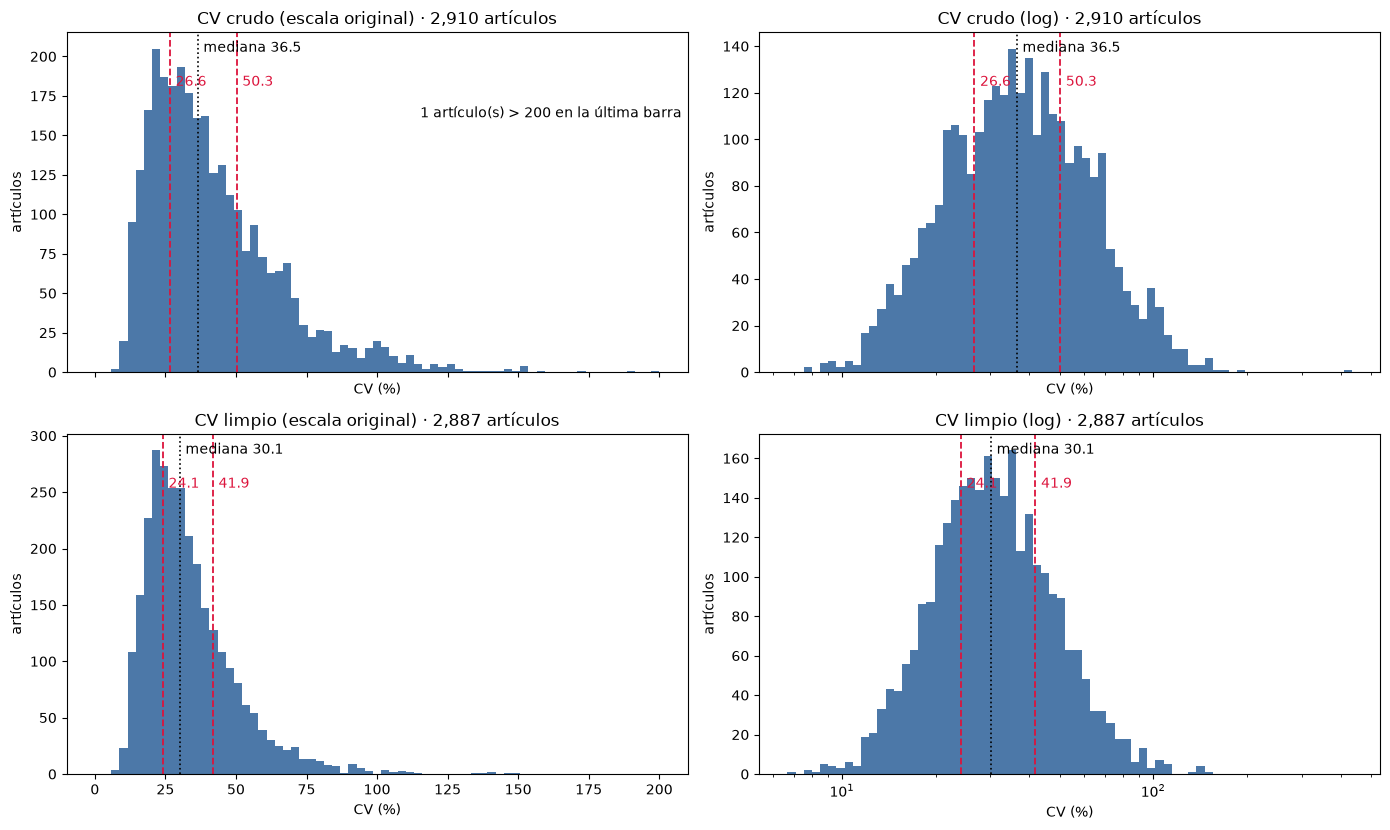

In [47]:
XYZ_CUTS = {"crudo": jenks_raw["thresholds"], "limpio": jenks_clean["thresholds"]}
fig = plot_cv_distributions(CVS, cuts=XYZ_CUTS)
plt.show()

## Etapa 6 · Velocidad y frecuencia de venta por artículo

Sin datos de inventario en el M5 no se calculan rotación ni días de inventario. En su lugar, dentro del ciclo de vida en train:

- **Velocidad de venta** = unidades vendidas ÷ días activos.
- **Frecuencia de venta** = días con venta > 0 ÷ días activos.

Dos versiones, como el CV:
- **Crudo** (`units_lc`): días activos = días con dato dentro del ciclo de vida; los quiebres cuentan como días sin venta. Es el análogo del nb 02 (`mean_daily_units` y 1 − `zero_share`), pero con el ciclo de vida recortado.
- **Limpio** (`units_treated`): días activos sin los días de quiebre (NaN). Las unidades y los días con venta son los mismos; solo cambia el denominador, así que velocidad y frecuencia limpias son ≥ crudas.

**Entra:** `train["units_lc"]`, `train["units_treated"]`. **Sale:** `rates_raw`, `rates_clean` (DataFrames) y `rates_train` (ambas juntas).
**Revisar:** la distribución de ambas medidas y cuánto suben al quitar los quiebres, sobre todo en los artículos de p₀ alto.

In [48]:
def sales_rates(units):
    """Días activos, unidades, días con venta, velocidad (unidades / día activo) y frecuencia (días con venta / día activo)."""
    arr = units.to_numpy()
    active = (~np.isnan(arr)).sum(axis=1)
    total = np.nansum(arr, axis=1)
    sale_days = (arr > 0).sum(axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        out = pd.DataFrame({"active_days": active, "units": total, "sale_days": sale_days,
                            "velocity": total / active, "frequency": sale_days / active}, index=units.index)
    return out


rates_raw = sales_rates(train["units_lc"])
display(rates_raw.head())

,active_days,units,sale_days,velocity,frequency
item_id,,,,,
FOODS_1_001,1456,9130.0,1277,6.270604,0.877060
FOODS_1_002,1456,5608.0,1399,3.851648,0.960852
FOODS_1_003,1456,10568.0,1434,7.258242,0.984890
FOODS_1_004,1174,111070.0,1103,94.608177,0.939523
FOODS_1_005,1372,15625.0,1021,11.388484,0.744169


In [49]:
rates_clean = sales_rates(train["units_treated"])
assert (rates_clean["units"] == rates_raw["units"]).all() and (rates_clean["sale_days"] == rates_raw["sale_days"]).all()
display(rates_clean.head())

,active_days,units,sale_days,velocity,frequency
item_id,,,,,
FOODS_1_001,1305,9130.0,1277,6.996169,0.978544
FOODS_1_002,1456,5608.0,1399,3.851648,0.960852
FOODS_1_003,1456,10568.0,1434,7.258242,0.984890
FOODS_1_004,1115,111070.0,1103,99.614350,0.989238
FOODS_1_005,1127,15625.0,1021,13.864241,0.905945


### Crudo frente a limpio

**Qué hace:** `compare_rates` junta ambas versiones con su cociente (limpio ÷ crudo) y el tercil de p₀; también trae, como referencia, las medidas del nb 02 sobre train sin recortar (`mean_daily_units` y 1 − `zero_share` de `describe_items`).
**Entra:** `rates_raw`, `rates_clean`, `min_days`, `agg`. **Sale:** `rates_train` (DataFrame).
**Revisar:** cuánto difiere el crudo del análogo del nb 02 (solo por el recorte del ciclo de vida) y cuánto sube el limpio.

In [50]:
from src.segmentation import describe_items


def compare_rates(rates_raw, rates_clean, min_days, nb02_like):
    """Velocidad y frecuencia crudas y limpias, su cociente, el tercil de p₀ y las medidas tipo nb 02."""
    out = pd.DataFrame({
        "velocity_raw": rates_raw["velocity"], "velocity_clean": rates_clean["velocity"],
        "frequency_raw": rates_raw["frequency"], "frequency_clean": rates_clean["frequency"],
        "active_days_raw": rates_raw["active_days"], "active_days_clean": rates_clean["active_days"],
    })
    out["velocity_ratio"] = out["velocity_clean"] / out["velocity_raw"]
    out["frequency_ratio"] = out["frequency_clean"] / out["frequency_raw"]
    out = out.join(min_days["p0_tercile"])
    out["velocity_nb02"] = nb02_like["mean_daily_units"].to_numpy()
    out["frequency_nb02"] = 1 - nb02_like["zero_share"].to_numpy()
    return out


nb02_like = describe_items(agg, START_D, TRAIN_END).set_index("item_id").reindex(rates_raw.index)
rates_train = compare_rates(rates_raw, rates_clean, min_days, nb02_like)
cols = ["velocity_nb02", "velocity_raw", "velocity_clean", "frequency_nb02", "frequency_raw", "frequency_clean"]
display(rates_train[cols].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3))
display(rates_train.groupby("p0_tercile")[["velocity_raw", "velocity_clean", "velocity_ratio",
                                            "frequency_raw", "frequency_clean", "frequency_ratio"]].median().round(3))
print(f"artículos que cambian (limpio ≠ crudo): {(rates_train['active_days_clean'] < rates_train['active_days_raw']).sum():,}")
print(f"crudo ≠ nb 02 (por el recorte del ciclo de vida): velocidad {(~np.isclose(rates_train['velocity_raw'], rates_train['velocity_nb02'])).sum():,}"
      f" · frecuencia {(~np.isclose(rates_train['frequency_raw'], rates_train['frequency_nb02'])).sum():,} artículos")

,velocity_nb02,velocity_raw,velocity_clean,frequency_nb02,frequency_raw,frequency_clean
count,3049.000,3049.000,3049.000,3049.000,3049.000,3049.000
mean,12.907,12.973,13.745,0.841,0.845,0.908
std,24.971,25.394,26.006,0.158,0.157,0.123
min,0.048,0.048,0.352,0.025,0.025,0.181
10%,1.567,1.577,1.719,0.607,0.612,0.728
25%,3.014,3.027,3.366,0.752,0.758,0.877
50%,6.065,6.096,6.784,0.893,0.897,0.961
75%,12.920,12.940,13.839,0.971,0.975,0.990
90%,28.025,28.171,29.371,0.993,0.995,0.997
max,573.269,622.896,628.051,1.000,1.000,1.000


,velocity_raw,velocity_clean,velocity_ratio,frequency_raw,frequency_clean,frequency_ratio
p0_tercile,,,,,,
T1 (p₀ bajo),11.355,11.416,1.000,0.988,0.993,1.000
T2 (p₀ medio),5.845,6.242,1.054,0.897,0.955,1.054
T3 (p₀ alto),2.375,2.966,1.172,0.692,0.811,1.172


artículos que cambian (limpio ≠ crudo): 1,984
crudo ≠ nb 02 (por el recorte del ciclo de vida): velocidad 1,428 · frecuencia 1,428 artículos


### Distribuciones

Velocidad en escala log (cola larga: hay artículos de < 1 y de cientos de unidades/día); frecuencia en escala original (0–1).

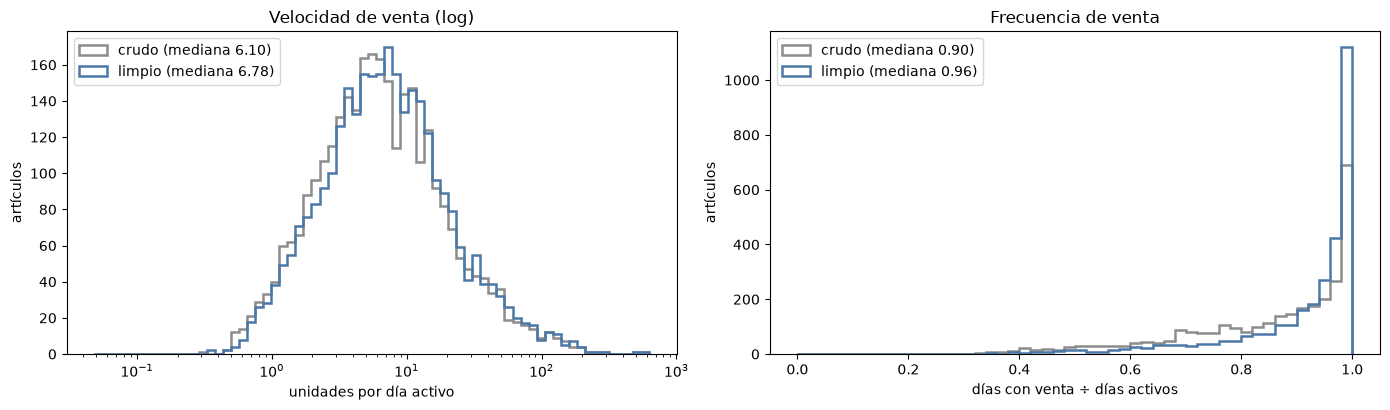

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
v = rates_train[["velocity_raw", "velocity_clean"]]
edges = np.logspace(np.log10(v.min().min()), np.log10(v.max().max()), 70)
for col, color, name in (("velocity_raw", "0.55", "crudo"), ("velocity_clean", "#4c78a8", "limpio")):
    axes[0].hist(rates_train[col], bins=edges, histtype="step", linewidth=1.8, color=color, label=f"{name} (mediana {rates_train[col].median():.2f})")
axes[0].set(xscale="log", title="Velocidad de venta (log)", xlabel="unidades por día activo", ylabel="artículos")
for col, color, name in (("frequency_raw", "0.55", "crudo"), ("frequency_clean", "#4c78a8", "limpio")):
    axes[1].hist(rates_train[col], bins=np.linspace(0, 1, 51), histtype="step", linewidth=1.8, color=color, label=f"{name} (mediana {rates_train[col].median():.2f})")
axes[1].set(title="Frecuencia de venta", xlabel="días con venta ÷ días activos", ylabel="artículos")
for ax in axes:
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

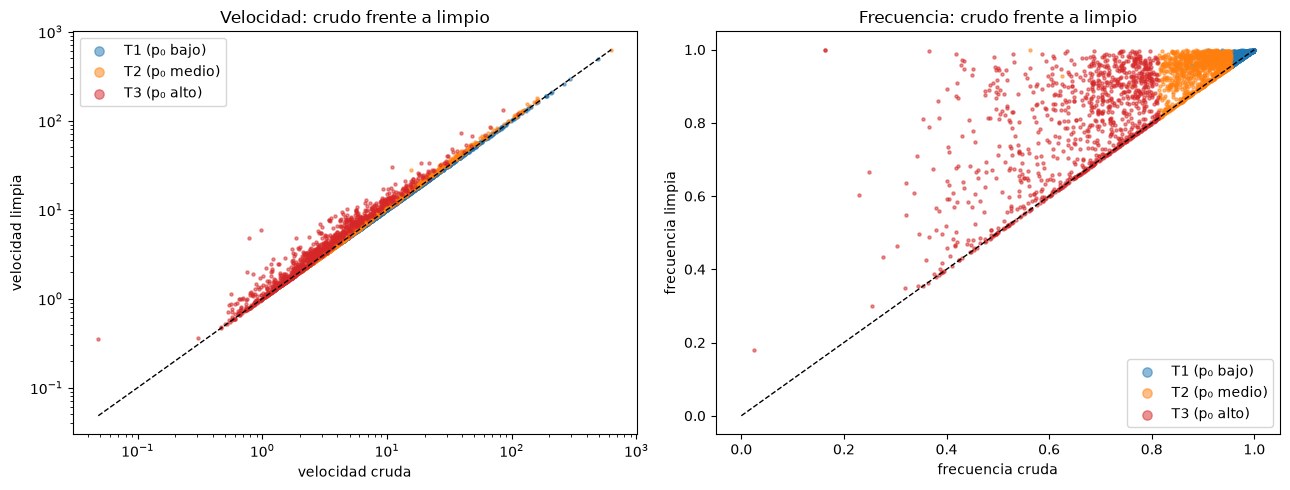

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (t, g), color in zip(rates_train.groupby("p0_tercile"), ["#1f77b4", "#ff7f0e", "#d62728"]):
    axes[0].scatter(g["velocity_raw"], g["velocity_clean"], s=5, alpha=0.5, color=color, label=t)
    axes[1].scatter(g["frequency_raw"], g["frequency_clean"], s=5, alpha=0.5, color=color, label=t)
lim_v = [rates_train["velocity_raw"].min(), rates_train["velocity_clean"].max()]
axes[0].plot(lim_v, lim_v, "k--", linewidth=1)
axes[0].set(xscale="log", yscale="log", xlabel="velocidad cruda", ylabel="velocidad limpia", title="Velocidad: crudo frente a limpio")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].set(xlabel="frecuencia cruda", ylabel="frecuencia limpia", title="Frecuencia: crudo frente a limpio")
for ax in axes:
    ax.legend(markerscale=3)
fig.tight_layout()
plt.show()

## Etapa 7 · Segmentos individuales

**Qué hace:** `segment_counts` cuenta los artículos de cada clase y su proporción (y, como referencia, su % del gasto de train). Se llama una vez por clasificación: ABC, XYZ crudo y XYZ limpio. `-` = sin clase XYZ (menos de 13 bloques válidos).
**Entra:** `abc_train`, `xyz_train`, `spend_item_train`. **Sale:** `counts_abc`, `counts_xyz_raw`, `counts_xyz_clean` (DataFrames).
**Revisar:** que cada tabla sume 3,049 artículos y el 100 % del gasto, y cómo cambia el reparto XYZ entre crudo y limpio.

In [53]:
def segment_counts(labels, spend, order):
    """Artículos, % de artículos y % del gasto por clase (`-` = sin clase)."""
    labels = labels.fillna("-")
    out = pd.DataFrame({"n_items": labels.value_counts(),
                        "spend": spend.groupby(labels.reindex(spend.index)).sum()})
    out = out.reindex([c for c in order + ["-"] if c in out.index])
    out["pct_items"] = out["n_items"] / out["n_items"].sum() * 100
    out["pct_spend"] = out["spend"] / out["spend"].sum() * 100
    out.loc["Total"] = out.sum()
    return out[["n_items", "pct_items", "pct_spend"]]


abc_labels = abc_train.set_index("item_id")["abc_class"]
counts_abc = segment_counts(abc_labels, spend_item_train, ["A", "B", "C"])
display(counts_abc.round(2))

,n_items,pct_items,pct_spend
abc_class,,,
A,593,19.45,60.03
B,795,26.07,23.99
C,1661,54.48,15.98
Total,3049,100.00,100.00


In [54]:
counts_xyz_raw = segment_counts(xyz_train["xyz_raw"], spend_item_train, ["X", "Y", "Z"])
display(counts_xyz_raw.round(2))

,n_items,pct_items,pct_spend
xyz_raw,,,
X,829,27.19,31.32
Y,1252,41.06,42.87
Z,829,27.19,25.28
-,139,4.56,0.52
Total,3049,100.00,100.00


In [55]:
counts_xyz_clean = segment_counts(xyz_train["xyz_clean"], spend_item_train, ["X", "Y", "Z"])
display(counts_xyz_clean.round(2))

,n_items,pct_items,pct_spend
xyz_clean,,,
X,893,29.29,33.61
Y,1311,43.00,42.68
Z,683,22.40,22.93
-,162,5.31,0.79
Total,3049,100.00,100.00


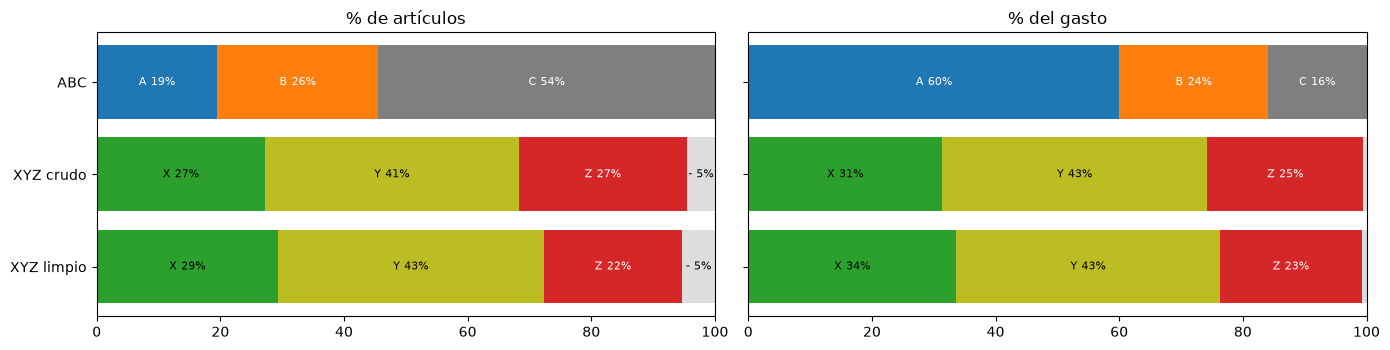

In [56]:
for t in (counts_abc, counts_xyz_raw, counts_xyz_clean):
    assert t.loc["Total", "n_items"] == len(spend_item_train) and np.isclose(t.loc["Total", "pct_spend"], 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
tables = {"ABC": counts_abc, "XYZ crudo": counts_xyz_raw, "XYZ limpio": counts_xyz_clean}
palette = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#7f7f7f", "X": "#2ca02c", "Y": "#bcbd22", "Z": "#d62728", "-": "#dddddd"}
for ax, col, title in zip(axes, ("pct_items", "pct_spend"), ("% de artículos", "% del gasto")):
    for y, (name, t) in enumerate(tables.items()):
        left = 0
        for cls, v in t.drop(index="Total")[col].items():
            ax.barh(y, v, left=left, color=palette[cls])
            if v >= 4:
                ax.text(left + v / 2, y, f"{cls} {v:.0f}%", ha="center", va="center", fontsize=8, color="white" if cls in "ABCZ" else "black")
            left += v
    ax.set(title=title, xlim=(0, 100), yticks=range(len(tables)), yticklabels=list(tables))
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

## Etapa 8 · Segmentos cruzados

### 8.1 · Tabla por artículo de cada versión

**Qué hace:** `item_table` arma una fila por artículo con su clase ABC, su clase XYZ de la versión, el segmento cruzado (`AX` … `CZ`; `A-`, `B-`, `C-` = sin XYZ) y las medidas del nb 02 en esa versión:
- `spend` y `usage_units`: gasto y unidades de train (iguales en ambas versiones).
- `cv`: CV crudo o limpio de la Etapa 4.
- `zero_share`: fracción de días con venta 0 sobre los días activos de la versión (crudo: ciclo de vida; limpio: sin quiebres). Es 1 − frecuencia de la Etapa 6.

**Entra:** `abc_train`, `xyz_train`, `rates_train`. **Sale:** `items_raw`, `items_clean` (DataFrames).
**Revisar:** que cada tabla tenga 3,049 artículos.

In [57]:
def item_table(abc, xyz_labels, cv, frequency, units):
    """Una fila por artículo con ABC, XYZ, segmento cruzado y las medidas del nb 02 de una versión."""
    out = abc.set_index("item_id")[["abc_class", "spend"]].copy()
    out["usage_units"] = units.reindex(out.index)
    out["xyz_class"] = xyz_labels.reindex(out.index).fillna("-")
    out["group"] = out["abc_class"] + out["xyz_class"]
    out["cv"] = cv.reindex(out.index)
    out["zero_share"] = 1 - frequency.reindex(out.index)
    return out.reset_index()


items_raw = item_table(abc_train, xyz_train["xyz_raw"], xyz_train["cv_raw"], rates_train["frequency_raw"], rates_raw["units"])
assert len(items_raw) == 3049
display(items_raw.head())

,item_id,abc_class,spend,usage_units,xyz_class,group,cv,zero_share
0,FOODS_3_586,A,1.119134e+06,709105.0,X,AX,13.744187,0.000000
1,FOODS_3_090,A,1.107543e+06,834680.0,Y,AY,42.318152,0.055224
2,FOODS_3_120,A,9.797473e+05,196737.0,Y,AY,40.198806,0.003306
3,FOODS_3_202,A,9.447823e+05,227126.0,X,AX,24.654309,0.037775
4,FOODS_3_587,A,6.689146e+05,272568.0,Z,AZ,51.211481,0.035714


In [58]:
items_clean = item_table(abc_train, xyz_train["xyz_clean"], xyz_train["cv_clean"], rates_train["frequency_clean"], rates_clean["units"])
assert len(items_clean) == 3049
display(items_clean.head())

,item_id,abc_class,spend,usage_units,xyz_class,group,cv,zero_share
0,FOODS_3_586,A,1.119134e+06,709105.0,X,AX,13.744187,0.000000
1,FOODS_3_090,A,1.107543e+06,834680.0,Y,AY,41.579250,0.047404
2,FOODS_3_120,A,9.797473e+05,196737.0,Y,AY,40.198806,0.003306
3,FOODS_3_202,A,9.447823e+05,227126.0,X,AX,22.715299,0.020280
4,FOODS_3_587,A,6.689146e+05,272568.0,Z,AZ,51.205492,0.033058


### 8.2 · Conteos y proporciones

**Qué hace:** `cross_counts` devuelve la matriz ABC × XYZ en artículos y en % del total, % por fila (cómo se reparte cada clase ABC entre X, Y, Z) y % por columna (cómo se reparte cada clase XYZ entre A, B, C).
**Entra:** `items_raw`, `items_clean`. **Sale:** `cross_raw`, `cross_clean` (dicts de DataFrames).
**Revisar:** que la matriz sume 3,049 y el tamaño de cada segmento cruzado.

In [59]:
def cross_counts(items):
    """Matriz ABC × XYZ: conteos, % del total, % por fila y % por columna."""
    cols = [c for c in ["X", "Y", "Z", "-"] if c in set(items["xyz_class"])]
    counts = pd.crosstab(items["abc_class"], items["xyz_class"]).reindex(columns=cols, fill_value=0)
    with_margins = counts.copy()
    with_margins["Total"] = with_margins.sum(axis=1)
    with_margins.loc["Total"] = with_margins.sum()
    return {
        "counts": with_margins,
        "pct_total": with_margins / with_margins.loc["Total", "Total"] * 100,
        "pct_row": with_margins.div(with_margins["Total"], axis=0) * 100,
        "pct_col": with_margins.div(with_margins.loc["Total"], axis=1) * 100,
    }


cross_raw = cross_counts(items_raw)
assert cross_raw["counts"].loc["Total", "Total"] == 3049
for name, t in cross_raw.items():
    print(f"CRUDO · {name}")
    display(t.round(2))

CRUDO · counts


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,198,255,140,0,593
B,261,337,197,0,795
C,370,660,492,139,1661
Total,829,1252,829,139,3049


CRUDO · pct_total


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,6.49,8.36,4.59,0.00,19.45
B,8.56,11.05,6.46,0.00,26.07
C,12.14,21.65,16.14,4.56,54.48
Total,27.19,41.06,27.19,4.56,100.00


CRUDO · pct_row


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,33.39,43.00,23.61,0.00,100.0
B,32.83,42.39,24.78,0.00,100.0
C,22.28,39.74,29.62,8.37,100.0
Total,27.19,41.06,27.19,4.56,100.0


CRUDO · pct_col


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,23.88,20.37,16.89,0.0,19.45
B,31.48,26.92,23.76,0.0,26.07
C,44.63,52.72,59.35,100.0,54.48
Total,100.00,100.00,100.00,100.0,100.00


In [60]:
cross_clean = cross_counts(items_clean)
assert cross_clean["counts"].loc["Total", "Total"] == 3049
for name, t in cross_clean.items():
    print(f"LIMPIO · {name}")
    display(t.round(2))

LIMPIO · counts


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,207,251,134,1,593
B,284,331,180,0,795
C,402,729,369,161,1661
Total,893,1311,683,162,3049


LIMPIO · pct_total


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,6.79,8.23,4.39,0.03,19.45
B,9.31,10.86,5.90,0.00,26.07
C,13.18,23.91,12.10,5.28,54.48
Total,29.29,43.00,22.40,5.31,100.00


LIMPIO · pct_row


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,34.91,42.33,22.60,0.17,100.0
B,35.72,41.64,22.64,0.00,100.0
C,24.20,43.89,22.22,9.69,100.0
Total,29.29,43.00,22.40,5.31,100.0


LIMPIO · pct_col


xyz_class,X,Y,Z,-,Total
abc_class,,,,,
A,23.18,19.15,19.62,0.62,19.45
B,31.80,25.25,26.35,0.00,26.07
C,45.02,55.61,54.03,99.38,54.48
Total,100.00,100.00,100.00,100.00,100.00


### 8.3 · Descripción de cada segmento (métricas del nb 02)

**Qué hace:** `profile_by` (la de la 6.1 del nb 02) agrupa los artículos y calcula `n_items`, `pct_items`, `spend`, `pct_spend`, `usage_units`, `pct_usage_units`, `mean_spend`, `median_spend`, `median_usage_units`, `mean_cv`, `median_cv`, `mean_zero_share` y `median_zero_share`. `segment_profile` la aplica en cuatro niveles: global, por clase ABC, por clase XYZ y por segmento cruzado.
**Entra:** `items_raw`, `items_clean`. **Sale:** `profile_raw`, `profile_clean` (DataFrames con índice `level, class`).
**Revisar:** que en cada nivel las clases sumen el total, y las medianas de CV y de `zero_share` por segmento.

In [61]:
def profile_by(df, by):
    """Perfil de los artículos de `df` agrupados por `by` (columna o arreglo), sobre sus totales (nb 02, 6.1)."""
    total_items, total_spend, total_usage = len(df), df["spend"].sum(), df["usage_units"].sum()
    out = df.groupby(by).agg(
        n_items=("item_id", "size"), spend=("spend", "sum"), usage_units=("usage_units", "sum"),
        mean_spend=("spend", "mean"), median_spend=("spend", "median"), median_usage_units=("usage_units", "median"),
        mean_cv=("cv", "mean"), median_cv=("cv", "median"),
        mean_zero_share=("zero_share", "mean"), median_zero_share=("zero_share", "median"),
    )
    out["pct_items"] = out["n_items"] / total_items * 100
    out["pct_spend"] = out["spend"] / total_spend * 100
    out["pct_usage_units"] = out["usage_units"] / total_usage * 100
    return out[["n_items", "pct_items", "spend", "pct_spend", "usage_units", "pct_usage_units", "mean_spend",
                "median_spend", "median_usage_units", "mean_cv", "median_cv", "mean_zero_share", "median_zero_share"]]


def segment_profile(items):
    """`profile_by` en cuatro niveles: global, ABC, XYZ y segmento cruzado."""
    order = [a + x for a in "ABC" for x in "XYZ-"]
    out = pd.concat({
        "global": profile_by(items, np.repeat("Total", len(items))),
        "abc_class": profile_by(items, "abc_class"),
        "xyz_class": profile_by(items, "xyz_class"),
        "group": profile_by(items, "group").reindex([g for g in order if g in set(items["group"])]),
    }, names=["level", "class"])
    for level, part in out.groupby(level="level"):
        assert part["n_items"].sum() == len(items) and np.isclose(part["pct_spend"].sum(), 100), level
    return out


PROFILE_FMT = {"n_items": "{:,.0f}", "spend": "{:,.0f}", "usage_units": "{:,.0f}", "mean_spend": "{:,.0f}",
               "median_spend": "{:,.0f}", "median_usage_units": "{:,.0f}", "mean_zero_share": "{:.3f}",
               "median_zero_share": "{:.3f}", "pct_items": "{:.1f}", "pct_spend": "{:.1f}",
               "pct_usage_units": "{:.1f}", "mean_cv": "{:.1f}", "median_cv": "{:.1f}"}
profile_raw = segment_profile(items_raw)
display(profile_raw.style.format(PROFILE_FMT).set_caption("CRUDO · perfil global, por clase y por segmento"))

In [62]:
profile_clean = segment_profile(items_clean)
display(profile_clean.style.format(PROFILE_FMT).set_caption("LIMPIO · perfil global, por clase y por segmento"))

### 8.4 · % del gasto por segmento cruzado

**Qué hace:** `spend_matrix` reparte el gasto de train en la matriz ABC × XYZ de cada versión (% del gasto total).
**Entra:** `items_raw`, `items_clean`. **Sale:** `spend_pct_raw`, `spend_pct_clean`.
**Revisar:** dónde se concentra el gasto y cómo se mueve entre versiones (solo dentro de cada fila ABC, porque ABC no cambia).

In [63]:
def spend_matrix(items):
    """% del gasto total por celda ABC × XYZ, con márgenes."""
    cols = [c for c in ["X", "Y", "Z", "-"] if c in set(items["xyz_class"])]
    t = pd.pivot_table(items, index="abc_class", columns="xyz_class", values="spend", aggfunc="sum",
                       margins=True, margins_name="Total", fill_value=0)
    return (t / items["spend"].sum() * 100).reindex(columns=cols + ["Total"])


spend_pct_raw = spend_matrix(items_raw)
spend_pct_clean = spend_matrix(items_clean)
display(pd.concat({"crudo": spend_pct_raw, "limpio": spend_pct_clean}, axis=1).round(1))

crudo                         limpio                        
xyz_class     X     Y     Z    -  Total      X     Y     Z    -  Total
abc_class                                                             
A          19.3  26.0  14.7  0.0   60.0   20.4  25.6  13.9  0.2   60.0
B           8.0  10.1   5.9  0.0   24.0    8.7   9.8   5.5  0.0   24.0
C           4.0   6.8   4.7  0.5   16.0    4.6   7.3   3.5  0.6   16.0
Total      31.3  42.9  25.3  0.5  100.0   33.6  42.7  22.9  0.8  100.0